### Jupyter - ułatwienia w pracy, pisaniu kodu

**Automatyczne uzupełnianie kodu (Tab)** <BR>
* Wpisz początek funkcji/zmiennej i naciśnij Tab

**Podpowiedzi argumentów funkcji (Shift + Tab)**
* Wpisz nazwę funkcji i otwórz nawias, a następnie naciśnij Shift + Tab
* Jeśli chcesz więcej szczegółów, naciśnij Shift + Tab większą liczbę razy.
    
**Wywołanie dokumentacji (?)**
* Dodaj ? przed lub po funkcji, aby zobaczyć dokumentację
    
**Pełne podświetlanie składni i podpowiedzi (Jupyter Lab)**
    
* pip install jupyterlab-lsp python-lsp-server

## Trzeci najbardziej zaawansowany przykład analizy
### Wykonamy krok po kroku kolejne kroki związane z:

1. **Importem danych**
2. **Zrozumieniem danych**
3. **Czyszczeniem danych**
4. **Budową modelu**
5. **Oceną modeu**
6. **Interpretacją modelu**

In [1]:
#Dodatkowe "ułatwienia" w ustawieniach wyświetlania i obsłudze ostrzeżeń

# Wyłączenie ramki wyświetlania (jeśli nam przeszkadza)
from IPython.display import display, HTML
display(HTML("<style>.output_scroll { height: auto !important; }</style>"))

# Wyłączenie ostrzeżeń dla analizy k-średnich
import warnings
warnings.simplefilter(action='ignore', category=UserWarning)

Upewnijmy się najpierw, jaki jest nasz bierzący folder roboczy

In [4]:
import os
print(os.getcwd())  # Wyświetli aktualny katalog roboczy

C:\Users\XYZ


In [1]:
# Obsługa zbiorów danych
import pandas as pd
import numpy as np

# Obsługa wykresów
import matplotlib.pyplot as plt
import seaborn as sns

# Uzupełnianie braków danych
from sklearn.impute import (SimpleImputer,KNNImputer)

# Wartosci odstające
from feature_engine.outliers import Winsorizer

# Skalowanie wartości zmiennych
from sklearn.preprocessing import MinMaxScaler

# Pokazuje wszystkie kolumny zbioru podczas podglądu
pd.set_option("display.max_columns", None) 

In [3]:
# Import danych z pliku csv do obiektu marketing_df - ramki danych 
marketing_df = pd.read_csv("marketing_campaign.csv", sep=None, engine="python")

### Pierwsze pytania do danych

1. Jaka jest struktura danych? 
2. Ile jest przypadków? Ile wierszy?
3. Co one oznaczają?
4. Jakie są typy kolumn w ramce danych?
5. Jaka jest liczba unikalnych wartości?

In [5]:
# Jaka jest liczba przypadków? Jaka jest liczba zmiennych?
print(marketing_df.shape)

(2240, 29)


In [4]:
# Wyświetl pierwszych 10 rekordów
marketing_df.head(10)

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0
5,7446,1967,Master,Together,62513.0,0,1,09-09-2013,16,520,42,98,0,42,14,2,6,4,10,6,0,0,0,0,0,0,3,11,0
6,965,1971,Graduation,Divorced,55635.0,0,1,13-11-2012,34,235,65,164,50,49,27,4,7,3,7,6,0,0,0,0,0,0,3,11,0
7,6177,1985,PhD,Married,33454.0,1,0,08-05-2013,32,76,10,56,3,1,23,2,4,0,4,8,0,0,0,0,0,0,3,11,0
8,4855,1974,PhD,Together,30351.0,1,0,06-06-2013,19,14,0,24,3,3,2,1,3,0,2,9,0,0,0,0,0,0,3,11,1
9,5899,1950,PhD,Together,5648.0,1,1,13-03-2014,68,28,0,6,1,1,13,1,1,0,0,20,1,0,0,0,0,0,3,11,0


Podstawowe sprawdzenie typów danych. To polecenie zwróci serię z nazwami kolumn i odpowiadającymi im typami danych.

In [5]:
# Podstawowe sprawdzenie typów danych
marketing_df.dtypes

ID                       int64
Year_Birth               int64
Education               object
Marital_Status          object
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer             object
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
AcceptedCmp3             int64
AcceptedCmp4             int64
AcceptedCmp5             int64
AcceptedCmp1             int64
AcceptedCmp2             int64
Complain                 int64
Z_CostContact            int64
Z_Revenue                int64
Response                 int64
dtype: object

**Dt_Customer ma typ "object" a jest to zmienna z datą. Zamienimy typ tej zmiennej.**

In [8]:
# Zamiana typu object na typ datetime dla zmiennej Dt_customer
marketing_df['Dt_Customer'] = pd.to_datetime(marketing_df['Dt_Customer'], format='%d-%m-%Y')

# Podstawowe sprawdzenie typów danych
marketing_df.dtypes

ID                              int64
Year_Birth                      int64
Education                      object
Marital_Status                 object
Income                        float64
Kidhome                         int64
Teenhome                        int64
Dt_Customer            datetime64[ns]
Recency                         int64
MntWines                        int64
MntFruits                       int64
MntMeatProducts                 int64
MntFishProducts                 int64
MntSweetProducts                int64
MntGoldProds                    int64
NumDealsPurchases               int64
NumWebPurchases                 int64
NumCatalogPurchases             int64
NumStorePurchases               int64
NumWebVisitsMonth               int64
AcceptedCmp3                    int64
AcceptedCmp4                    int64
AcceptedCmp5                    int64
AcceptedCmp1                    int64
AcceptedCmp2                    int64
Complain                        int64
Z_CostContac

In [9]:
# Sprawdzenie liczby unikalnych wartości
marketing_df.nunique()

ID                     2240
Year_Birth               59
Education                 5
Marital_Status            8
Income                 1974
Kidhome                   3
Teenhome                  3
Dt_Customer             663
Recency                 100
MntWines                776
MntFruits               158
MntMeatProducts         558
MntFishProducts         182
MntSweetProducts        177
MntGoldProds            213
NumDealsPurchases        15
NumWebPurchases          15
NumCatalogPurchases      14
NumStorePurchases        14
NumWebVisitsMonth        16
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp5              2
AcceptedCmp1              2
AcceptedCmp2              2
Complain                  2
Z_CostContact             1
Z_Revenue                 1
Response                  2
dtype: int64

**Dwie zmienne mają tylko jedną wartość (są stałe) możemy je usunąć z analizy**

In [10]:
# Usuwamy z tabeli zmienne bez zmienności 
marketing_df.drop(columns=['Z_CostContact', 'Z_Revenue'], inplace=True)

In [11]:
# Ponowne sprawdzenie liczby unikalnych wartości
marketing_df.nunique()

ID                     2240
Year_Birth               59
Education                 5
Marital_Status            8
Income                 1974
Kidhome                   3
Teenhome                  3
Dt_Customer             663
Recency                 100
MntWines                776
MntFruits               158
MntMeatProducts         558
MntFishProducts         182
MntSweetProducts        177
MntGoldProds            213
NumDealsPurchases        15
NumWebPurchases          15
NumCatalogPurchases      14
NumStorePurchases        14
NumWebVisitsMonth        16
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp5              2
AcceptedCmp1              2
AcceptedCmp2              2
Complain                  2
Response                  2
dtype: int64

### Ważna decyzja

**Rola zmiennych w analizie**

In [12]:
# Zmienna zawierająca Identyfikator
idVar = ['ID']
print(idVar)

['ID']


In [13]:
# Zmienna dodatkowa
additional = ['Response']

In [14]:
# Zmienne jakościowe to zmienne typu object oraz te, które mają dwie wartości (Tak/Nie - w tym przypadku 1/0)
categ_vars = [var for var in marketing_df.columns if marketing_df[var].dtype == "object" 
              or (marketing_df[var].nunique() <= 2 and var not in additional)]

# Wyświetlenie listy zmiennych jakościowych
print(categ_vars)

['Education', 'Marital_Status', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain']


In [15]:
# Zmienne czasowe
temporal_vars = ['Year_Birth', 'Dt_Customer']

# Wyświetlenie listy zmiennych czasowych
print(temporal_vars)

['Year_Birth', 'Dt_Customer']


In [16]:
# Zmienne ilościowe
num_vars = [var for var in marketing_df.columns if var not in categ_vars and var not in temporal_vars 
            and var != 'ID' and var not in additional]

# Wyświetlenie listy zmiennych ilościowych
print(num_vars)

['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth']


### Ocena jakości zbioru danych

1. Raport braków danych
2. Analiza rozkładów zmienne ilościowe - histogramy, wykres ramkowy, statystyki
3. Analiza rozkładów zmienne jakościowe - histogramy, tabela liczności
4. Ocena pod kątem wartości odstających i kategorii o małej liczności

In [17]:
# Tworzenie raportu braków danych
missing_report = pd.DataFrame({
    'Liczba braków': marketing_df.isnull().sum(),
    'Procent braków': (marketing_df.isnull().mean() * 100).round(2)
})

# Wyświetlenie raportu braków danych
print(missing_report)

                     Liczba braków  Procent braków
ID                               0            0.00
Year_Birth                       0            0.00
Education                        0            0.00
Marital_Status                   0            0.00
Income                          24            1.07
Kidhome                          0            0.00
Teenhome                         0            0.00
Dt_Customer                      0            0.00
Recency                          0            0.00
MntWines                         0            0.00
MntFruits                        0            0.00
MntMeatProducts                  0            0.00
MntFishProducts                  0            0.00
MntSweetProducts                 0            0.00
MntGoldProds                     0            0.00
NumDealsPurchases                0            0.00
NumWebPurchases                  0            0.00
NumCatalogPurchases              0            0.00
NumStorePurchases              

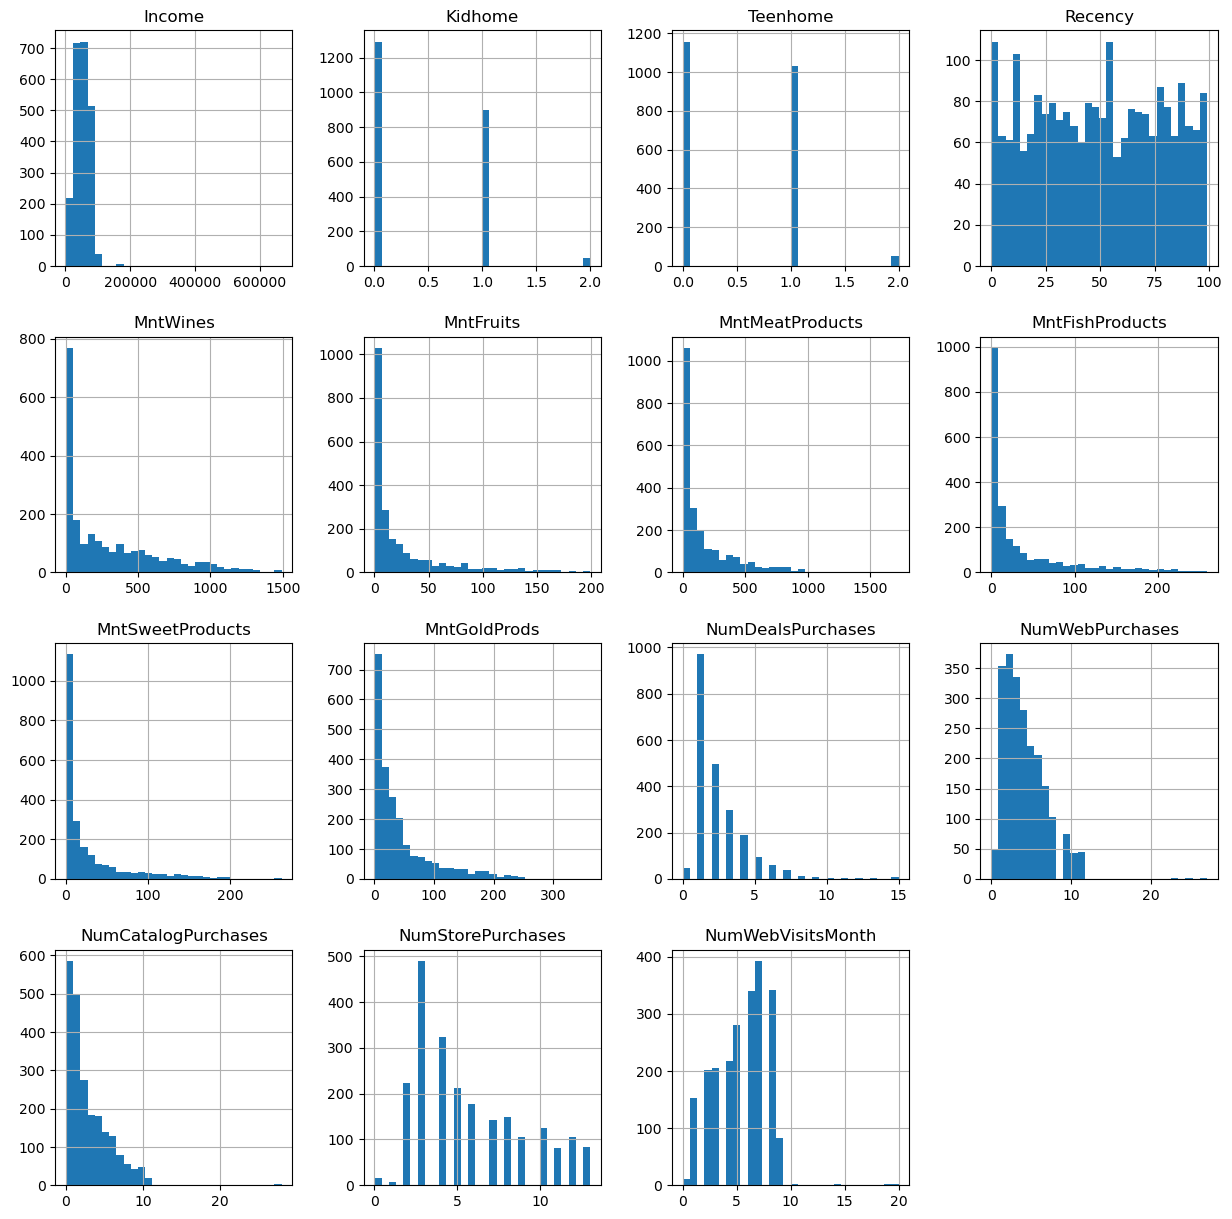

In [18]:
# Analiza rozkładów zmiennych
# Histogramy dla zmiennych ilościowych

marketing_df[num_vars].hist(bins=30, figsize=(15,15))
plt.show()

In [19]:
def plot_box_strip(df, variables, hue=None):
    """
    Tworzy wykresy pudełkowe z nakładającymi się wykresami strip dla podanych zmiennych.
    
    Parametry:
    - df: DataFrame zawierający dane
    - variables: lista nazw kolumn dla zmiennych ilościowych
    - hue: opcjonalna zmienna grupująca (kategoryczna)
    """
    for var in variables:
        plt.figure(figsize=(8, 6))
        
        # Wykres pudełkowy
        sns.boxplot(data=df, y=var, x=hue, fliersize=0, color='green')

        # Wykres strip
        sns.stripplot(data=df, y=var, x=hue, jitter=0.1, alpha=0.3, color='k', dodge=True if hue else False)
        
        plt.title(f'Wykres pudełkowy: {var}')
        plt.xlabel(hue if hue else '')
        plt.ylabel(var)
        plt.show()

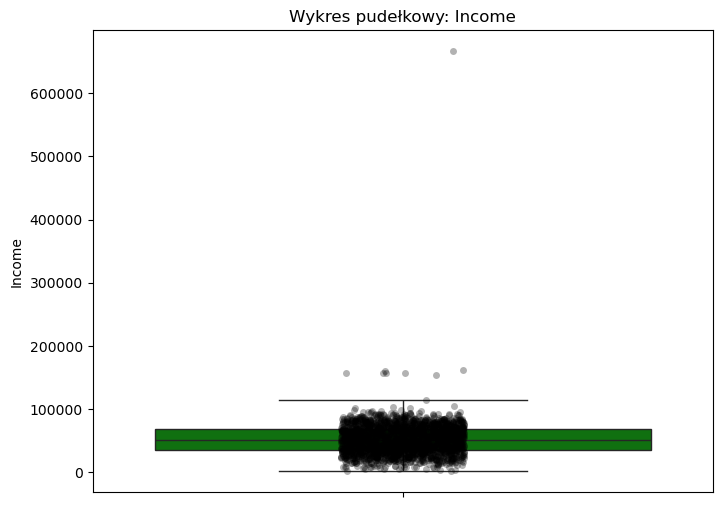

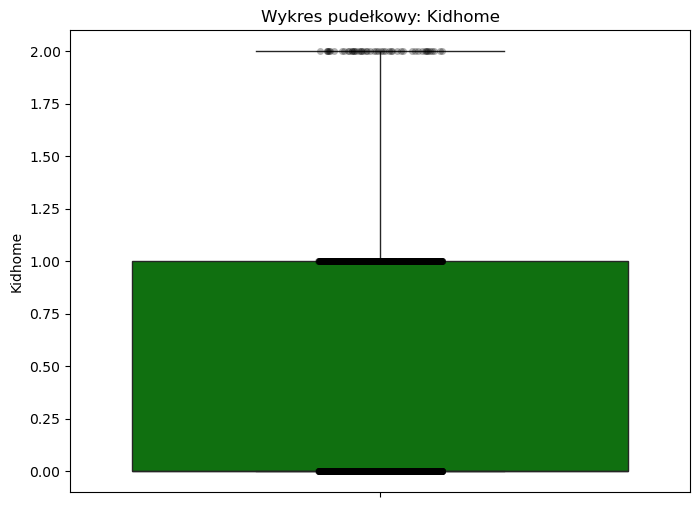

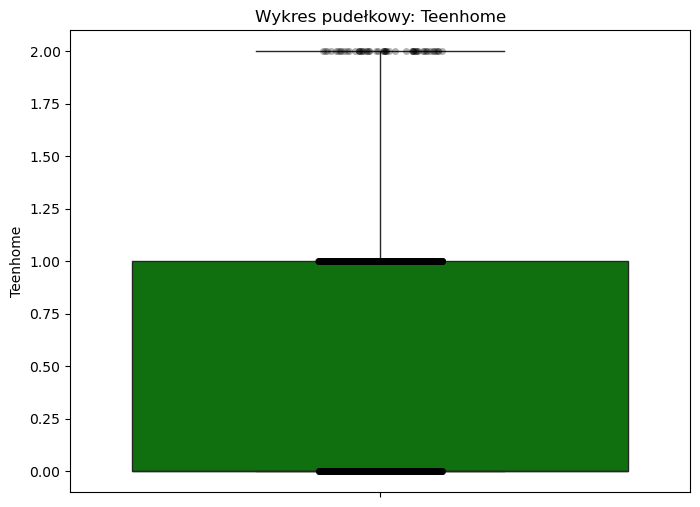

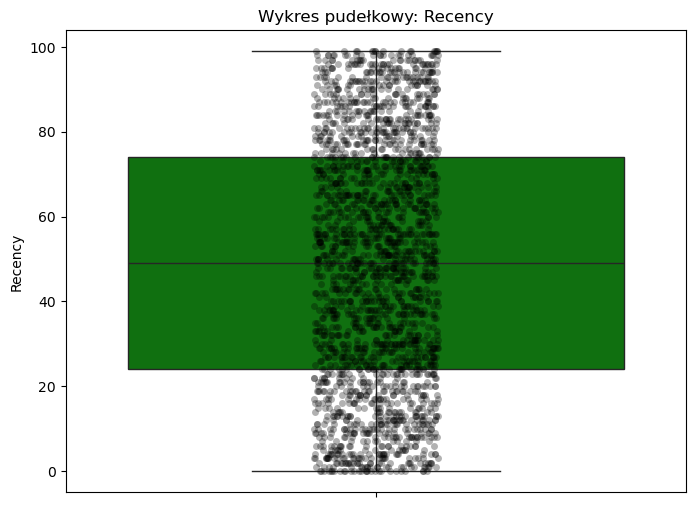

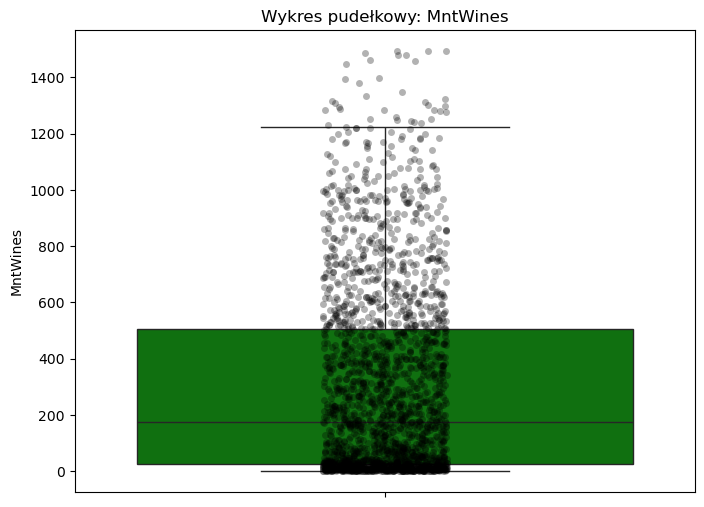

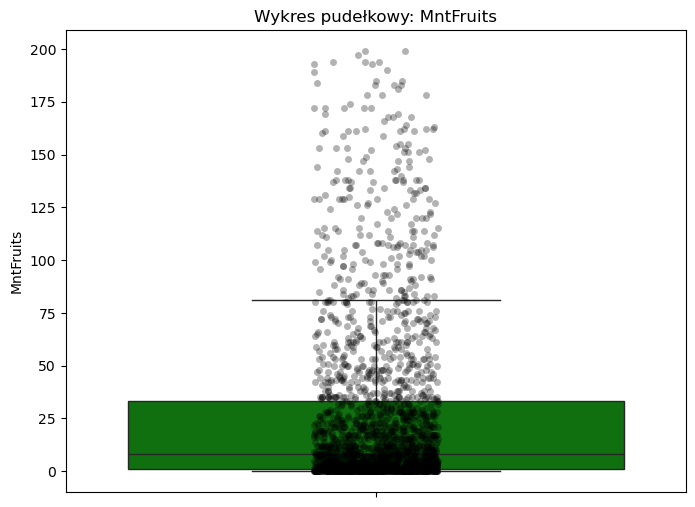

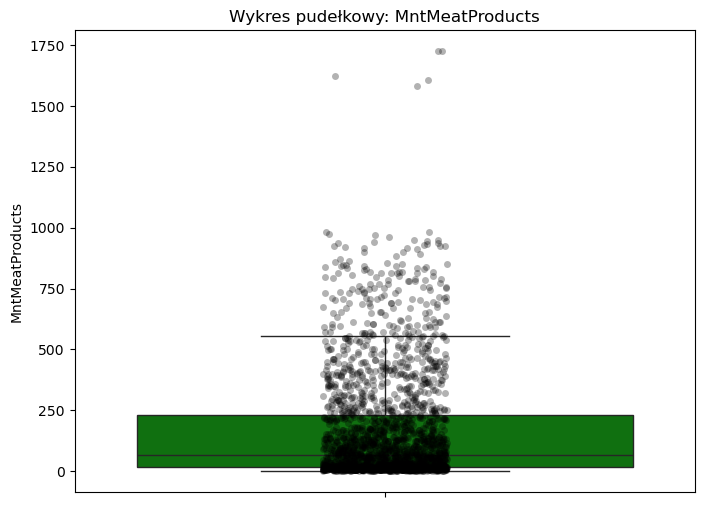

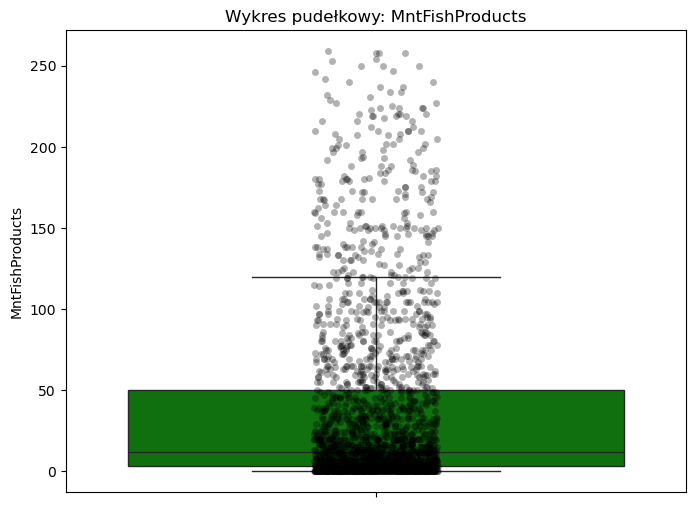

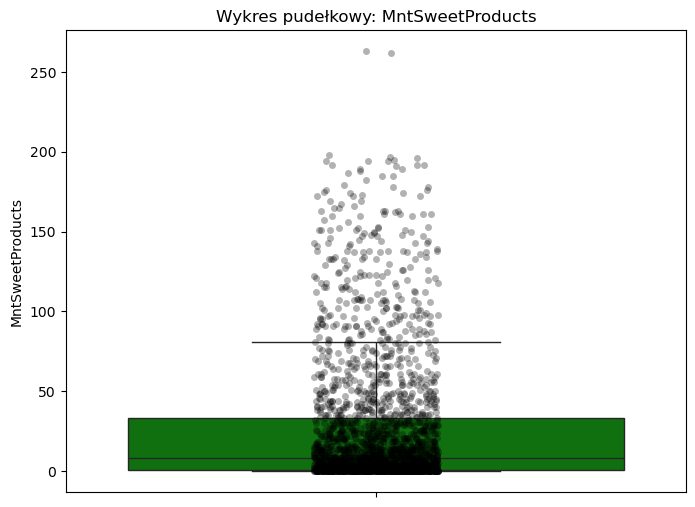

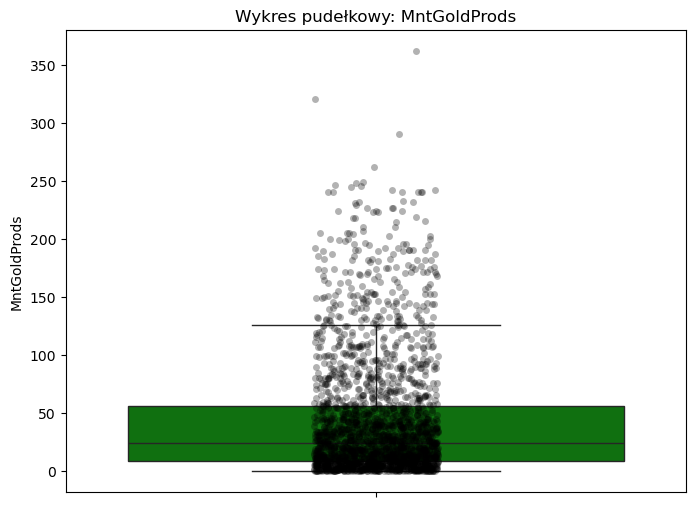

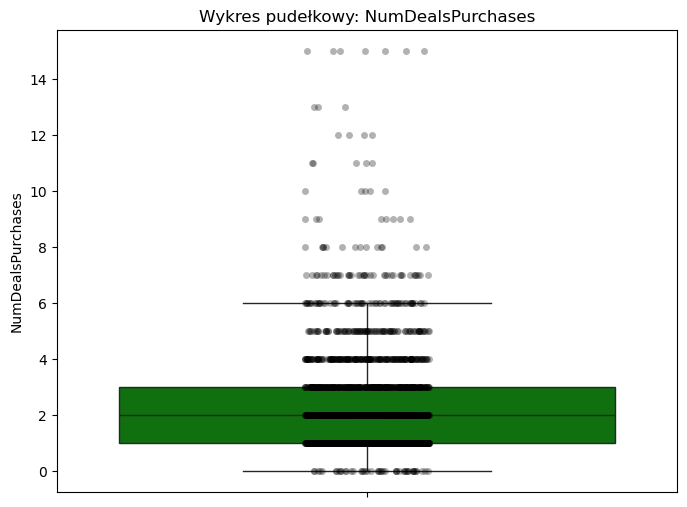

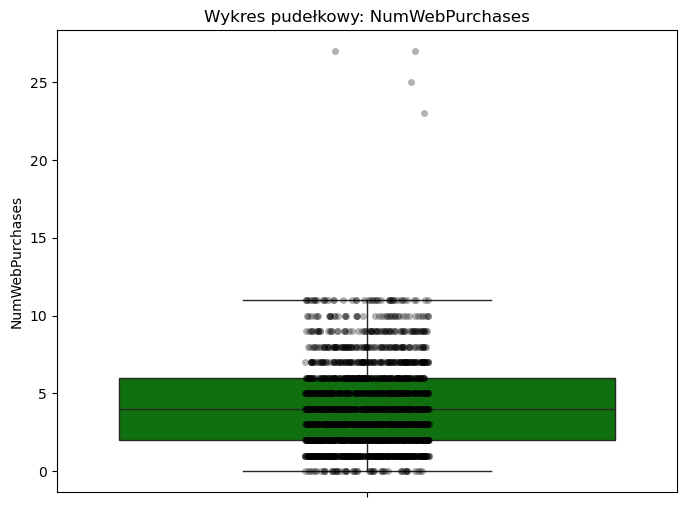

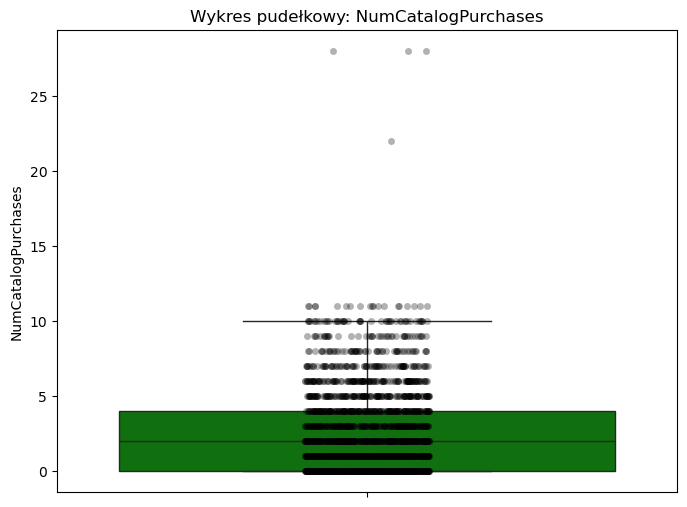

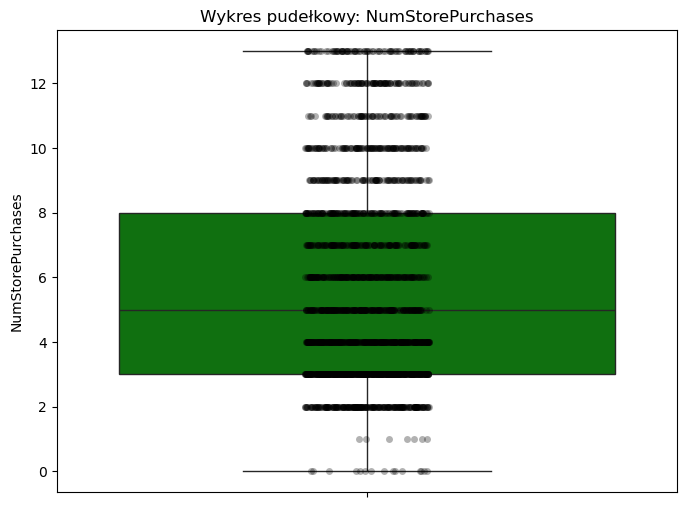

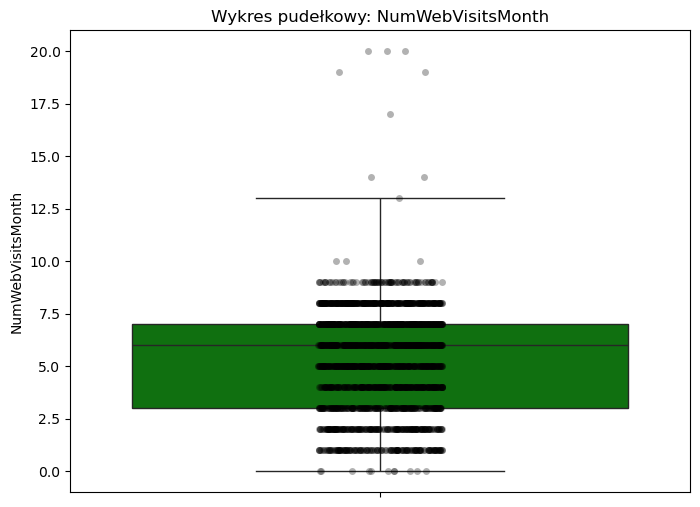

In [20]:
plot_box_strip(marketing_df,num_vars)

In [21]:
# Podsumowanie podstwowych statystyk

marketing_df[num_vars].describe()

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth
count,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,27.062946,44.021875,2.325000,4.084821,2.662054,5.790179,5.316518
std,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,41.280498,52.167439,1.932238,2.778714,2.923101,3.250958,2.426645
min,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,1.000000,9.000000,1.000000,2.000000,0.000000,3.000000,3.000000
50%,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,8.000000,24.000000,2.000000,4.000000,2.000000,5.000000,6.000000
75%,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,33.000000,56.000000,3.000000,6.000000,4.000000,8.000000,7.000000
max,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,362.000000,15.000000,27.000000,28.000000,13.000000,20.000000


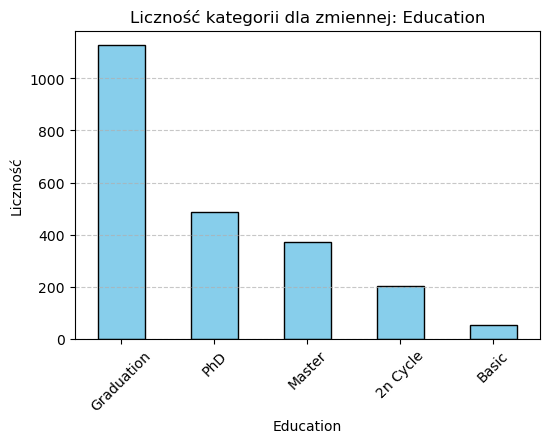

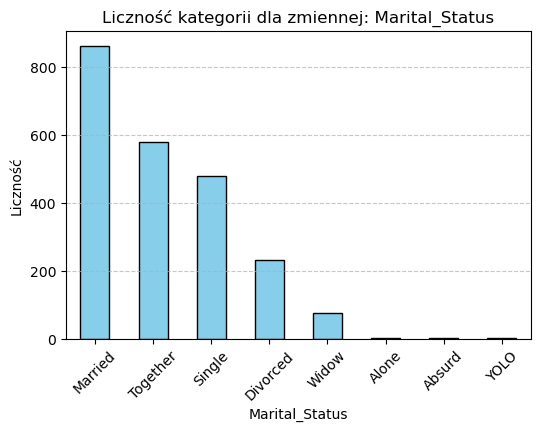

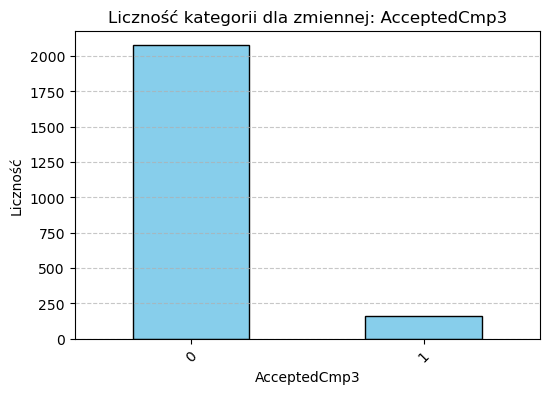

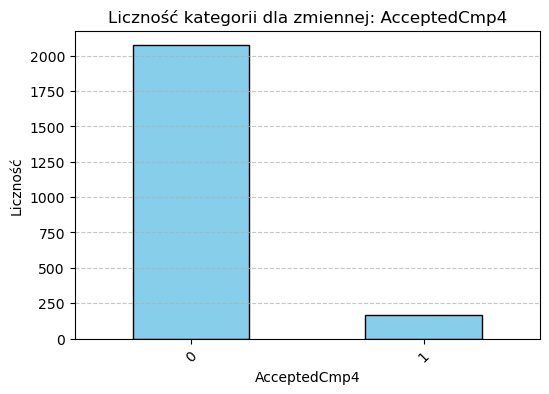

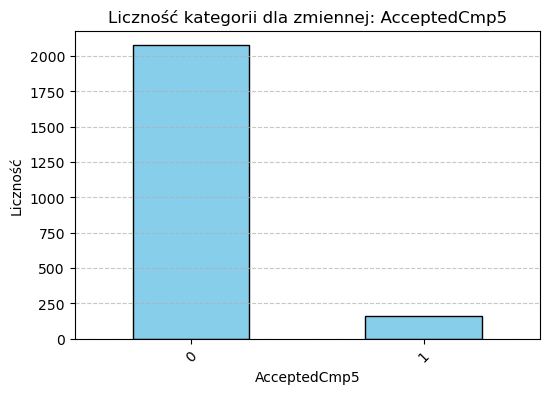

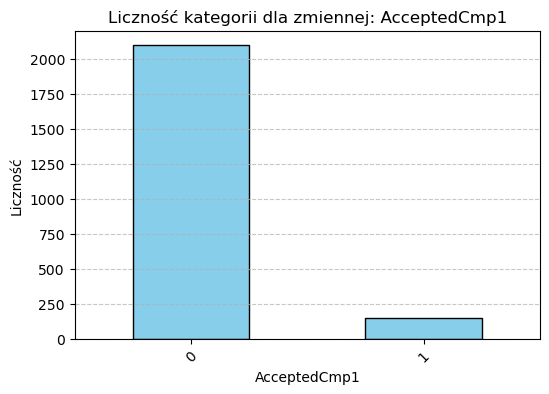

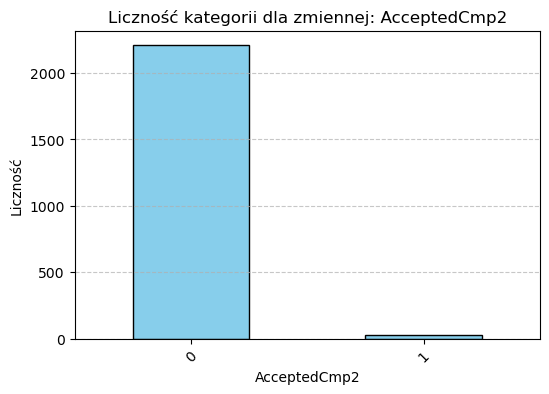

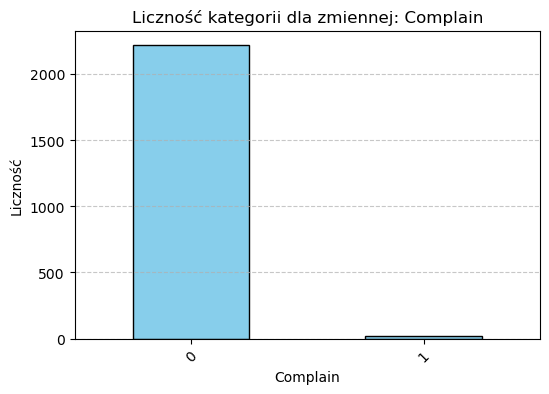

In [22]:
# Zmienne jakościowe
# Tworzenie wykresów słupkowych dla każdej zmiennej jakościowej
for var in categ_vars:
    plt.figure(figsize=(6, 4))
    marketing_df[var].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(f'Liczność kategorii dla zmiennej: {var}')
    plt.xlabel(var)
    plt.ylabel('Liczność')
    plt.xticks(rotation=45)  # Obrót etykiet kategorii dla czytelności
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

## Zrozumieliśmy dane teraz zaczynamy ich czyszczenie
### Na początek braki danych

1. Zmienne z niewielkim odsetkiem braków za pomocą mediany
2. Zmienne z większym odsetkiem za pomocą techniki KNN

In [23]:
# Uzupełnianie braków danych
# strategy='median' - braki uzupełniamy za pomocą mediany
simple_imputer= SimpleImputer(strategy='median')
marketing_df['Income']=simple_imputer.fit_transform(marketing_df[['Income']])

### Kolejny krok to wartości odstające

1. Wartości ekstremalnie nietypowe być może będziemy musieli usunąć z analizy
2. Wartości spoza zakresu "obcinamy" do granic uznanych za typowe

In [24]:
# Usunięcie przypadków, gdzie Income > 300000
marketing_df = marketing_df[marketing_df['Income'] <= 300000]

1a. Pod rozwagę można wziać kwestię czy inne przypadki nie powinny zostać usunięte z analizy?

In [25]:
# capping_method='iqr' - metoda oparta na rozstępie kwartylowym
# fold=1.5 - parametr sterujacy szerokocią przycinania 
# tail='both' → obcina wartości odstające zarówno z lewej (dolne wartości), jak i z prawej strony (górne wartości).

winsorizer = Winsorizer(capping_method='iqr', fold=1.5, tail='both')
marketing_df[num_vars] = winsorizer.fit_transform(marketing_df[num_vars])

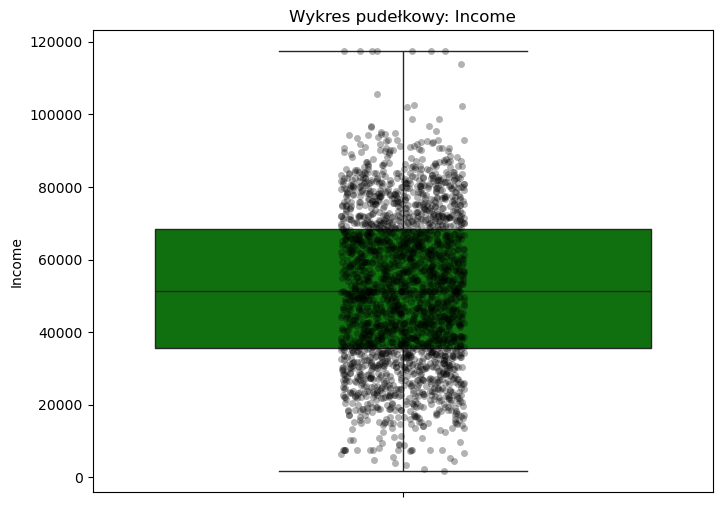

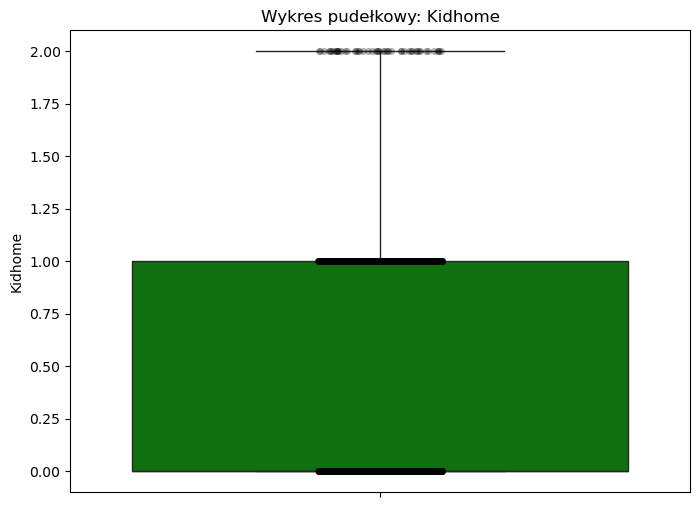

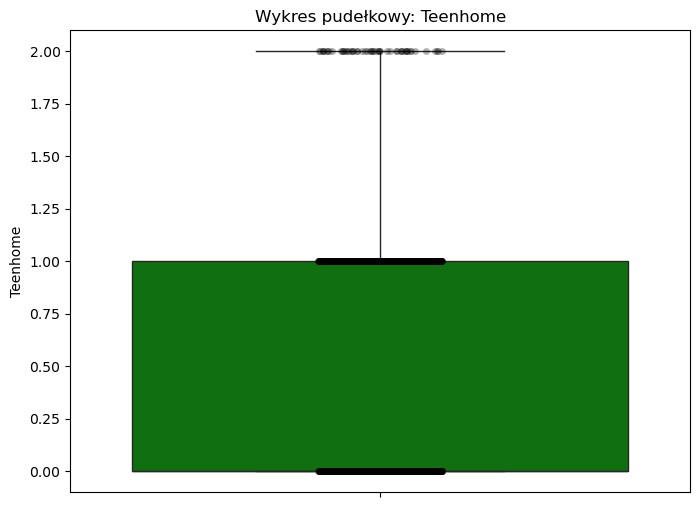

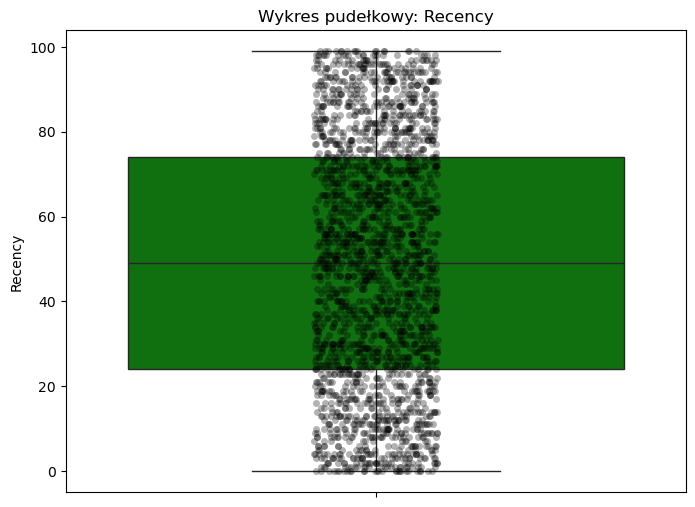

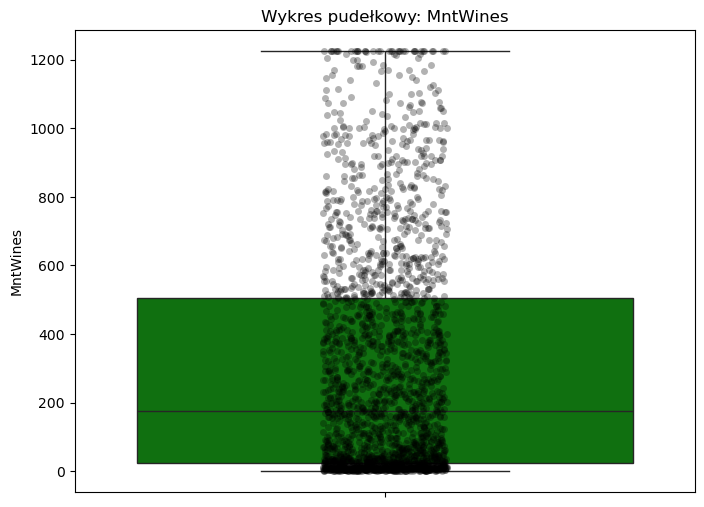

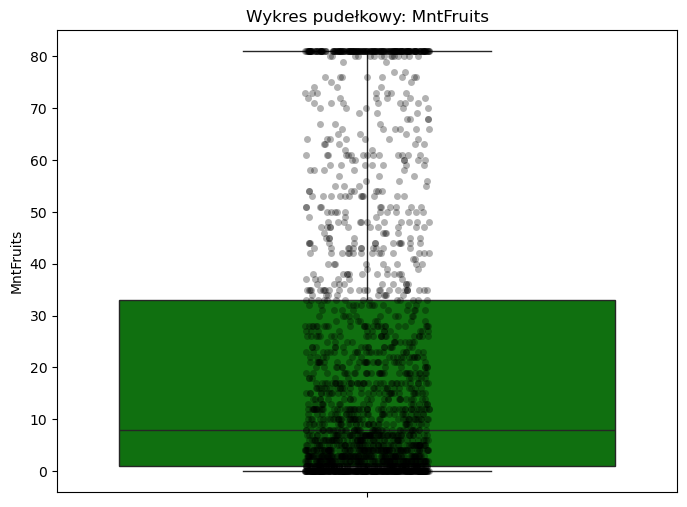

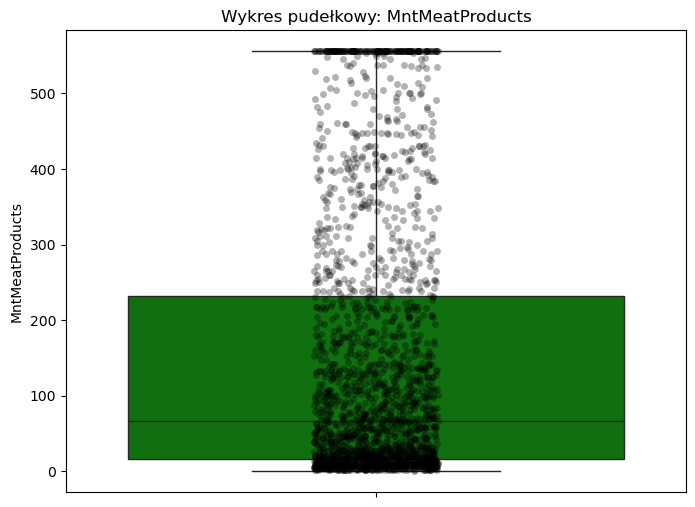

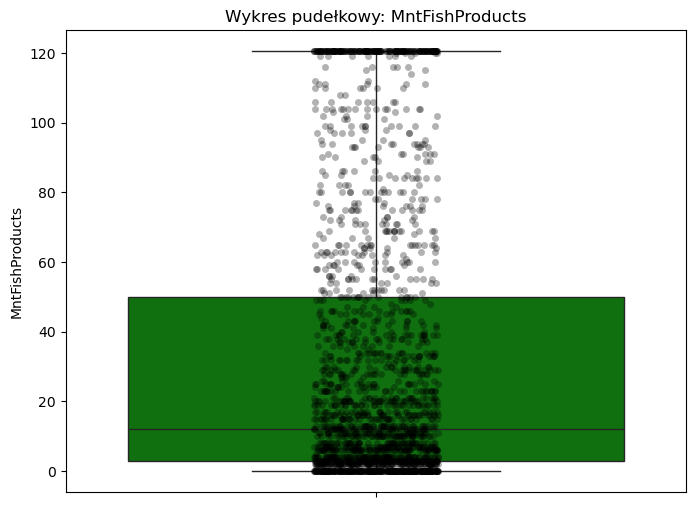

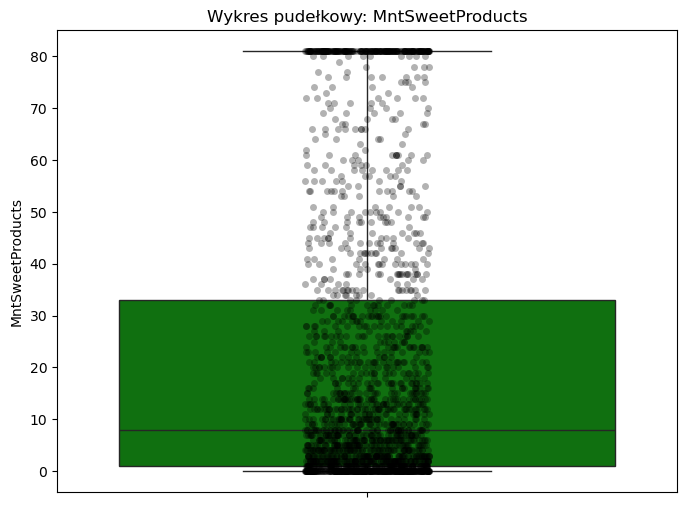

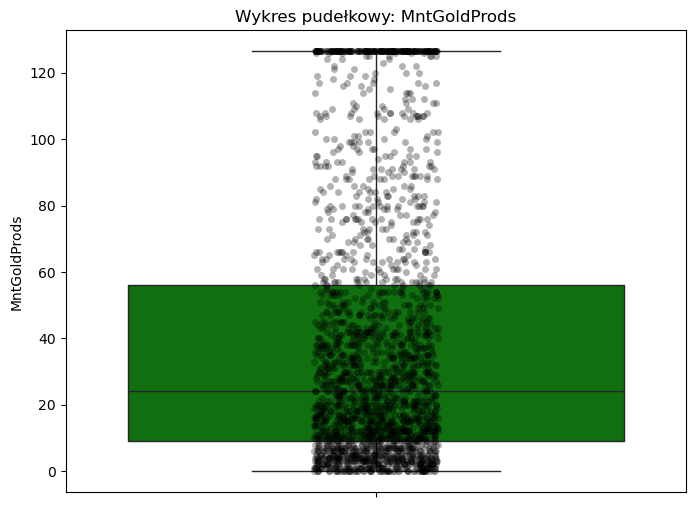

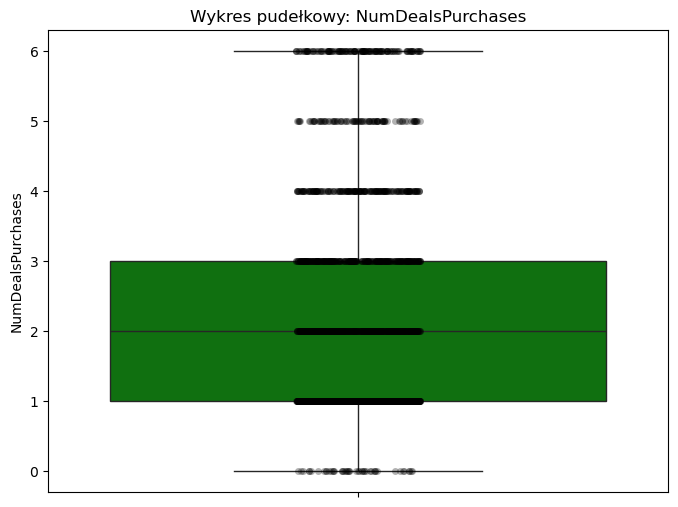

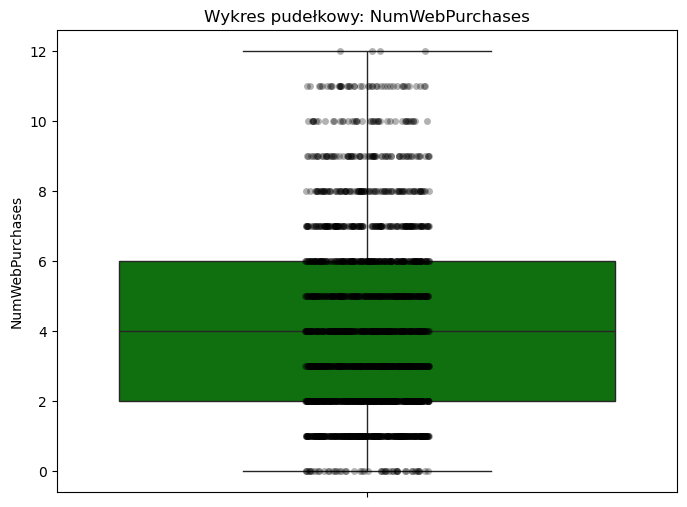

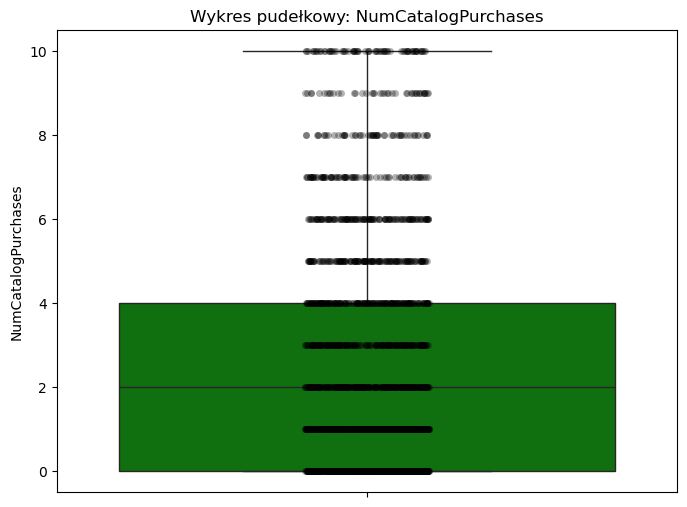

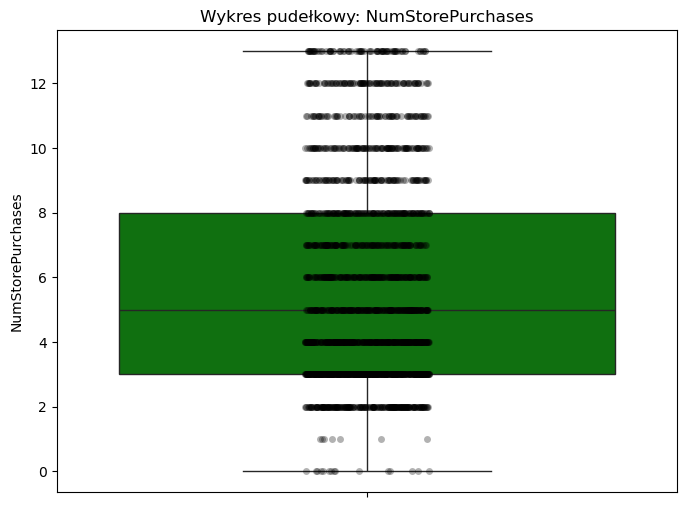

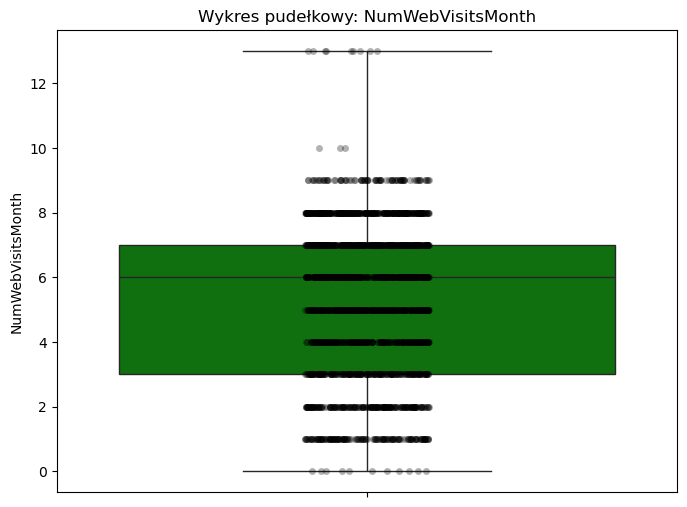

In [26]:
# Wykresy ramka-wąsy analiza pod kątem wartości odstających - sprawdzamy czy wartości "opanowane"
plot_box_strip(marketing_df,num_vars)

### Wróćmy do analizy zmiennych jakościowych 

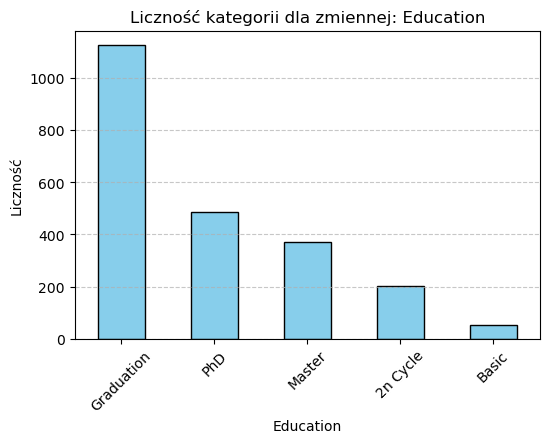

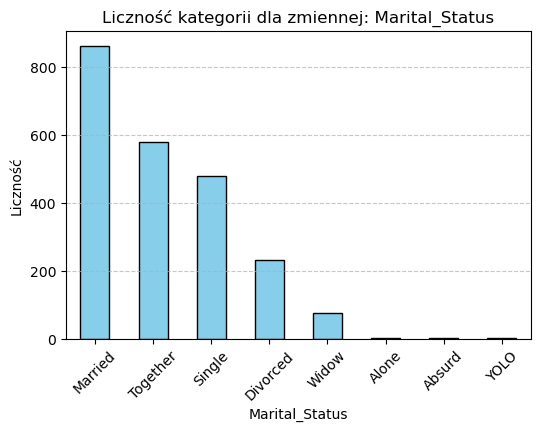

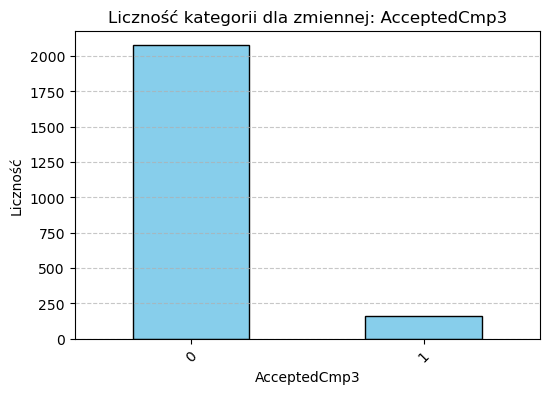

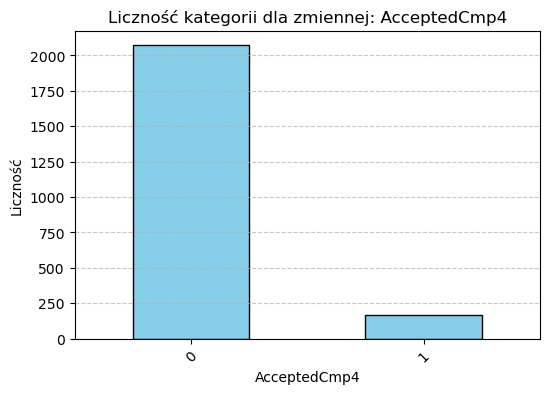

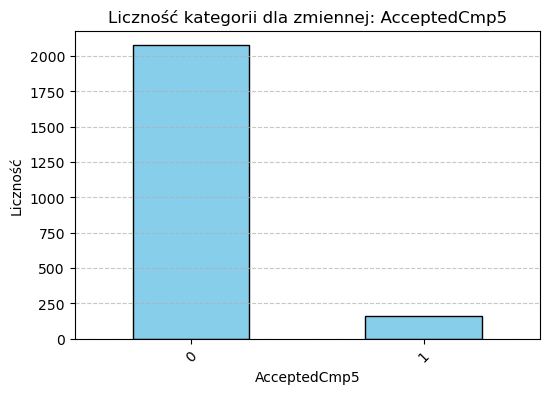

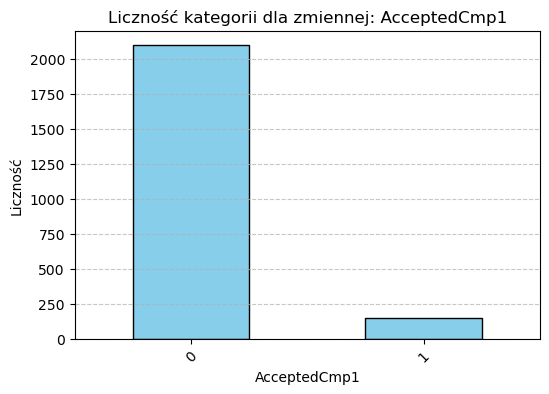

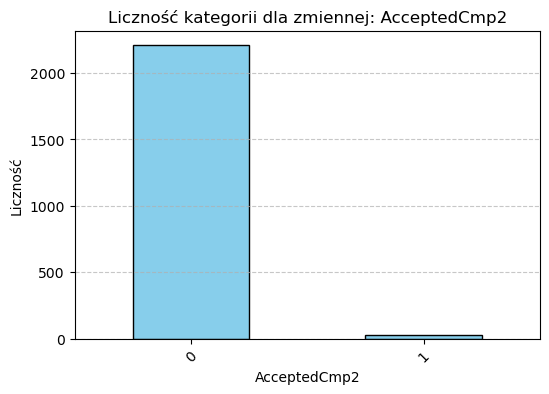

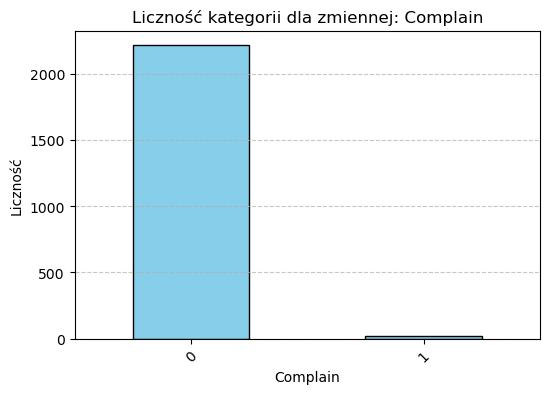

In [27]:
# Zmienne jakościowe
# Tworzenie wykresów słupkowych dla każdej zmiennej jakościowej
for var in categ_vars:
    plt.figure(figsize=(6, 4))
    marketing_df[var].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(f'Liczność kategorii dla zmiennej: {var}')
    plt.xlabel(var)
    plt.ylabel('Liczność')
    plt.xticks(rotation=45)  # Obrót etykiet kategorii dla czytelności
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

**Zamienimy zmienną Education na zmienną z dwiema klasami - lepiej i gorzej wykształceni**

In [28]:
marketing_df['IsAdvancedDegree'] = marketing_df['Education'].isin(['PhD', 'Master', '2n Cycle']).astype(int)

# Podgląd wyników
print(marketing_df[['Education', 'IsAdvancedDegree']].head())

    Education  IsAdvancedDegree
0  Graduation                 0
1  Graduation                 0
2  Graduation                 0
3  Graduation                 0
4         PhD                 1


**Zamienimy zmienną Związek na dwie klasy "Razem" oraz "Osobno". Klasy o małej liczności przypisane zostaną do klasy "Osobno"**

In [29]:
# Tworzenie zmiennej IsTogether (1 - w związku, 0 - poza związkiem)
marketing_df['IsTogether'] = marketing_df['Marital_Status'].isin(['Married', 'Together']).astype(int)

# Podgląd wyników
print(marketing_df[['Marital_Status', 'IsTogether']].head())

  Marital_Status  IsTogether
0         Single           0
1         Single           0
2       Together           1
3       Together           1
4        Married           1


**Zmienne opisujące akceptację kampanii to zmenne "rzadkie" (sparse data) - lepiej jest zsumować ich wartości**

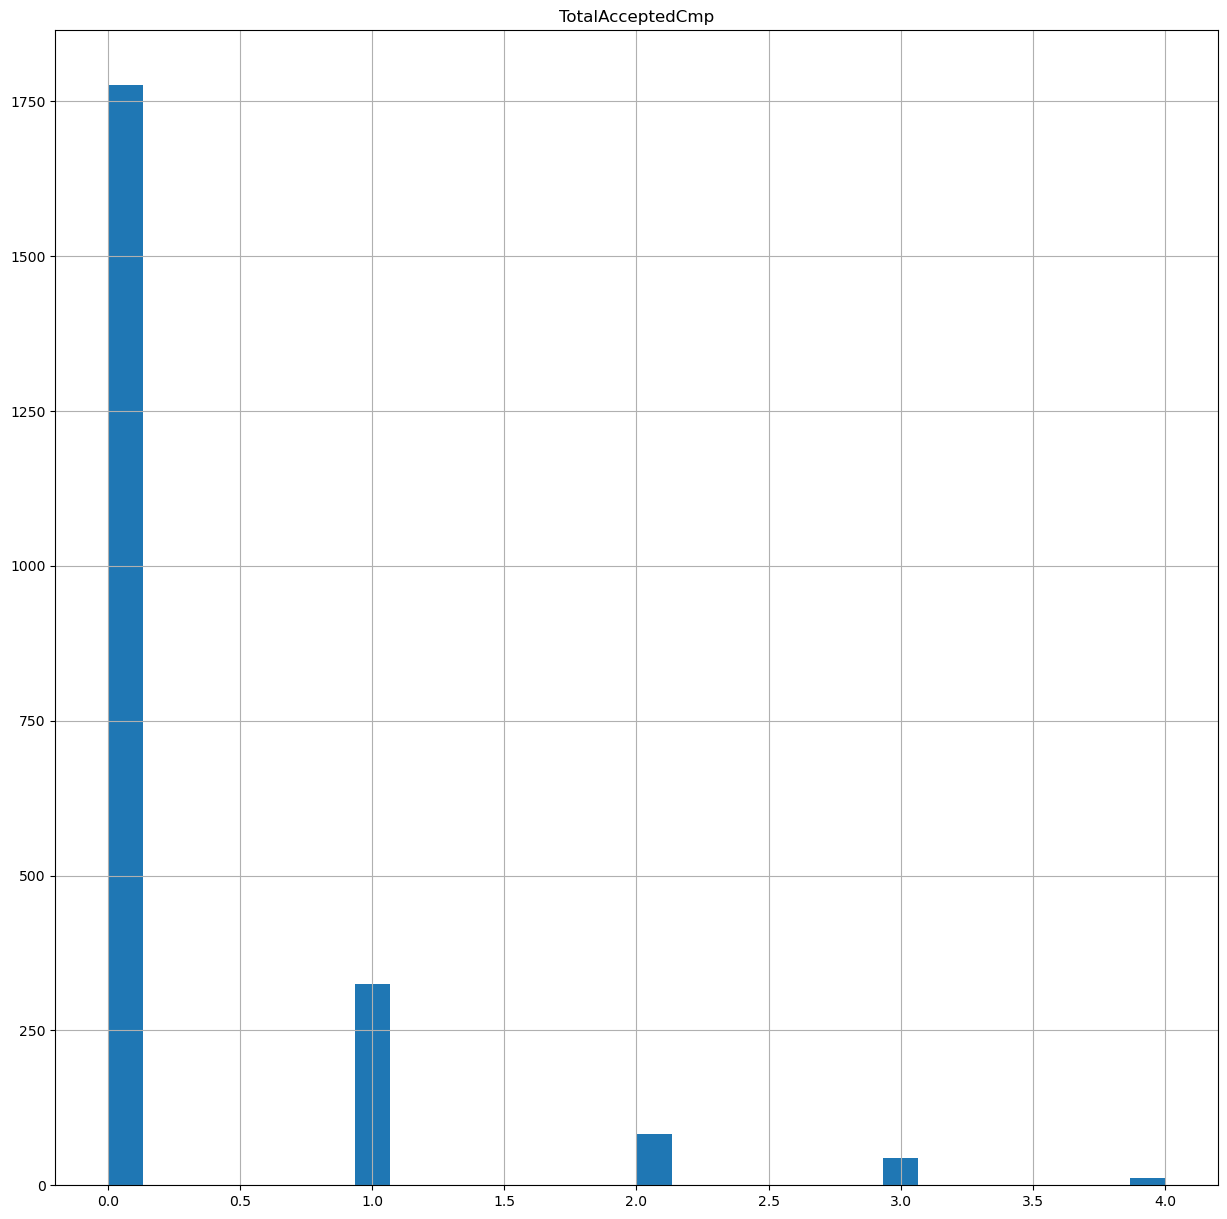

In [30]:
# Tworzenie zmiennej sumującej akceptację kampanii
# TotalAcceptedCmp będzie zawierać liczbę kampanii, które dana osoba zaakceptowała (od 0 do 5)
marketing_df['TotalAcceptedCmp'] = (
    marketing_df['AcceptedCmp1'] + 
    marketing_df['AcceptedCmp2'] + 
    marketing_df['AcceptedCmp3'] + 
    marketing_df['AcceptedCmp4'] + 
    marketing_df['AcceptedCmp5']
)

marketing_df[['TotalAcceptedCmp']].hist(bins=30, figsize=(15,15))
plt.show()

**Niewielka liczba osób akceptujących powyżej jednej kampainii**

In [31]:
# Tworzenie zmiennej 0-1: czy zaakceptowano przynajmniej jedną kampanię
marketing_df['AcceptedAnyCmp'] = (marketing_df['TotalAcceptedCmp'] > 0).astype(int)

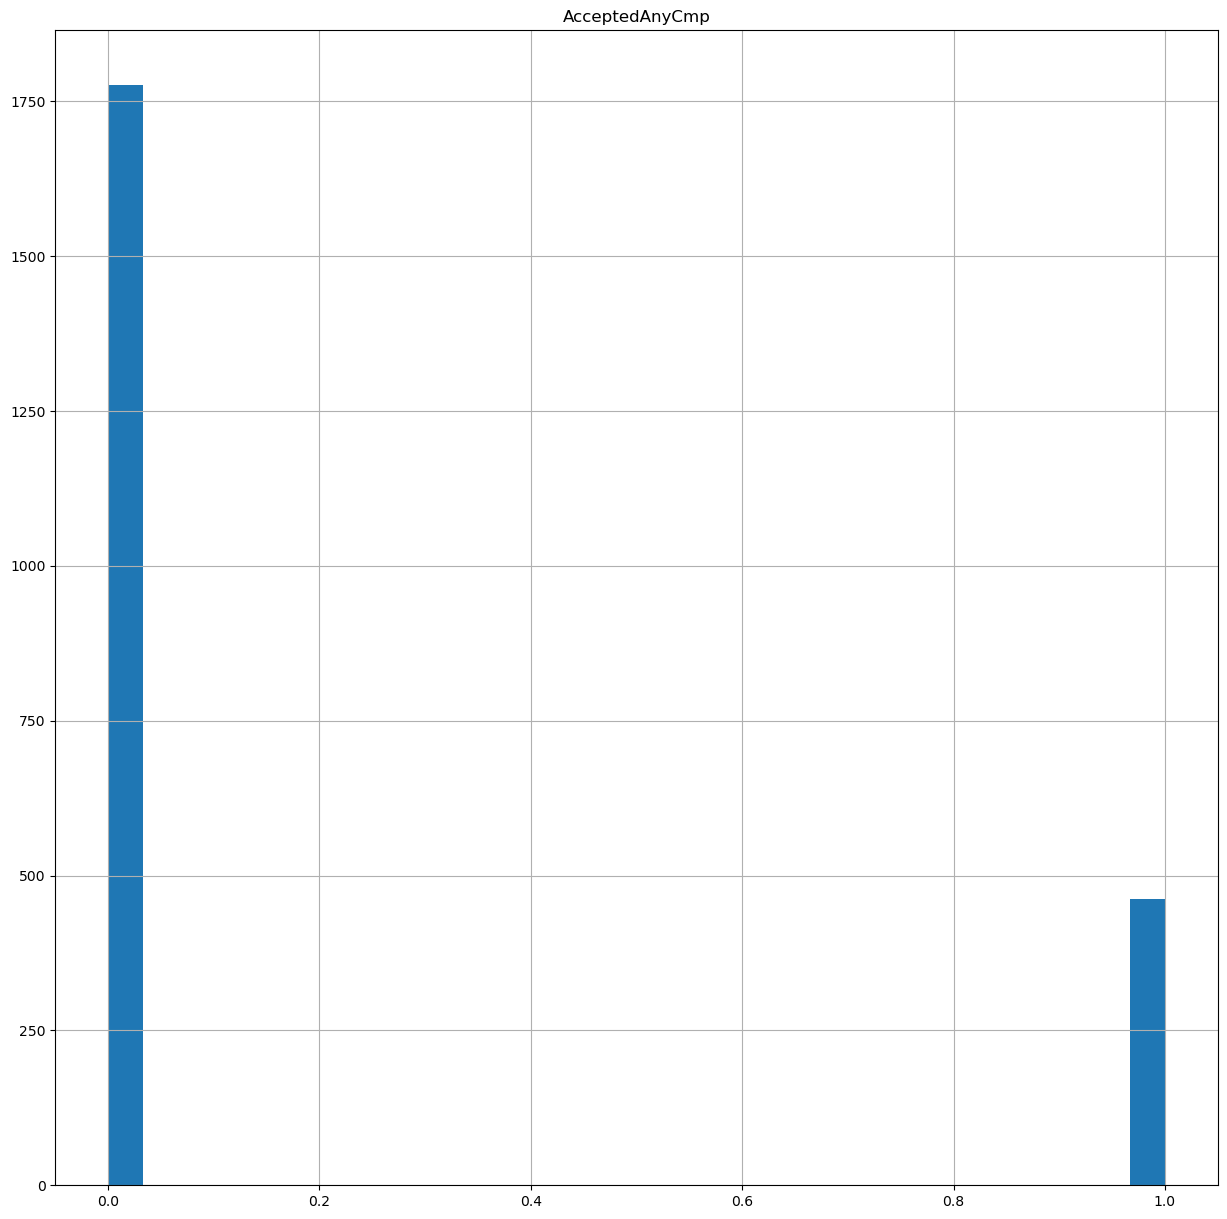

In [32]:
marketing_df[['AcceptedAnyCmp']].hist(bins=30, figsize=(15,15))
plt.show()

**Zmienną Complain wyrzucamy z analizy**

### Zajmiemy się teraz zmiennymi czasowymi

temporal_vars = ['Year_Birth', 'Dt_Customer']

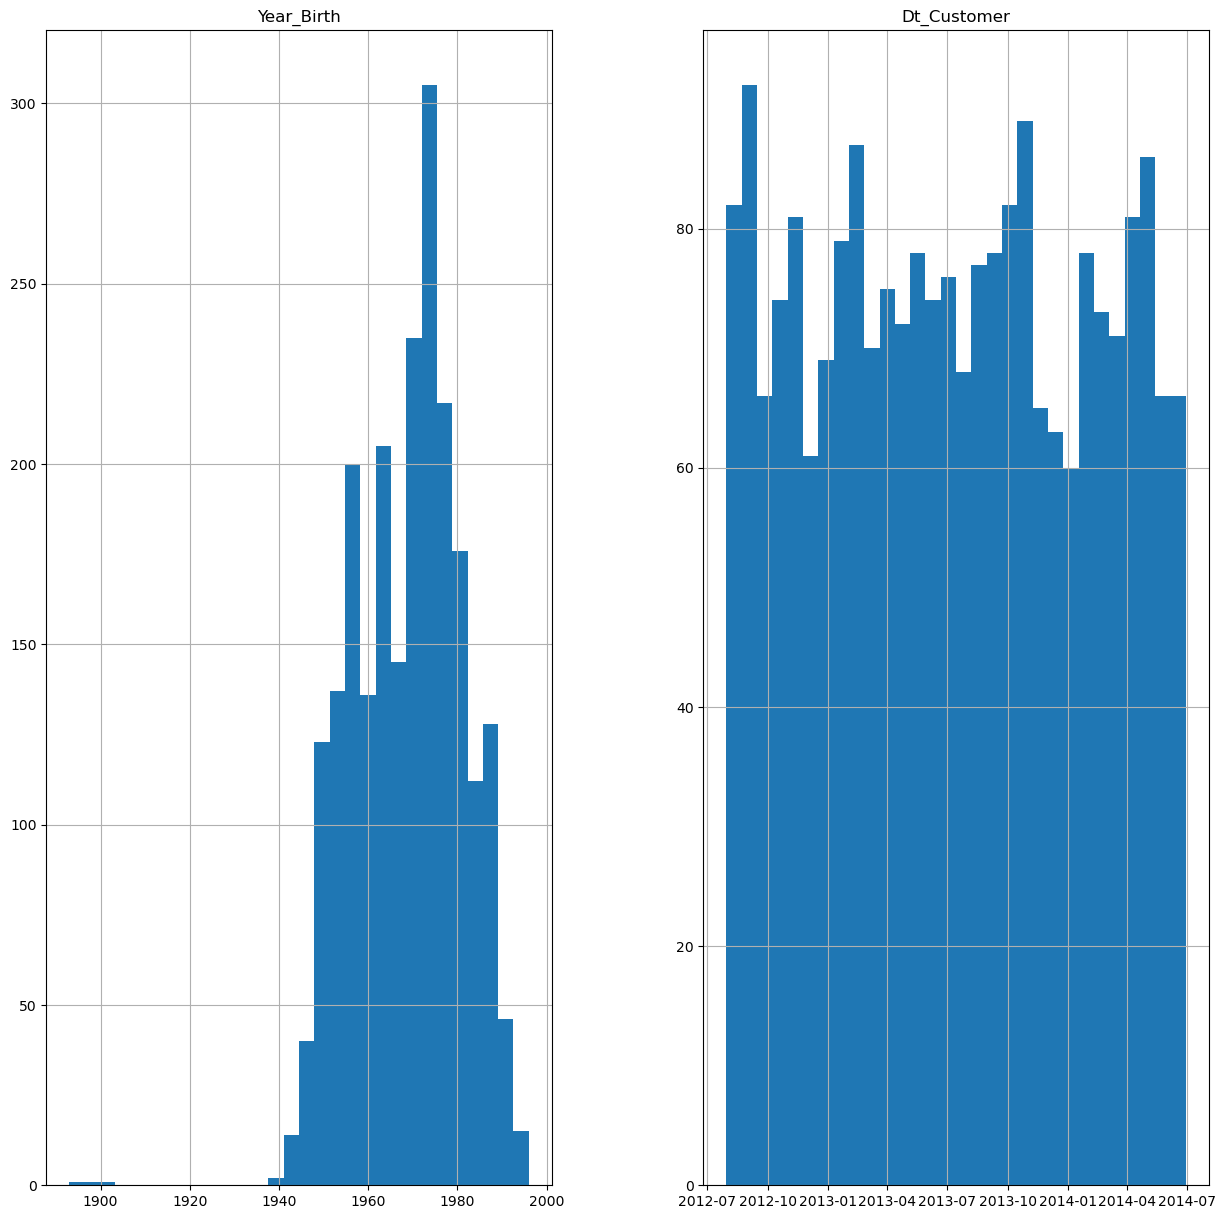

In [33]:
marketing_df[temporal_vars].hist(bins=30, figsize=(15,15))
plt.show()

### Obliczymy wiek klienta oraz jak długo w dniach jest klientem sklepu - zakładamy że mamy 1 stycznia 2015

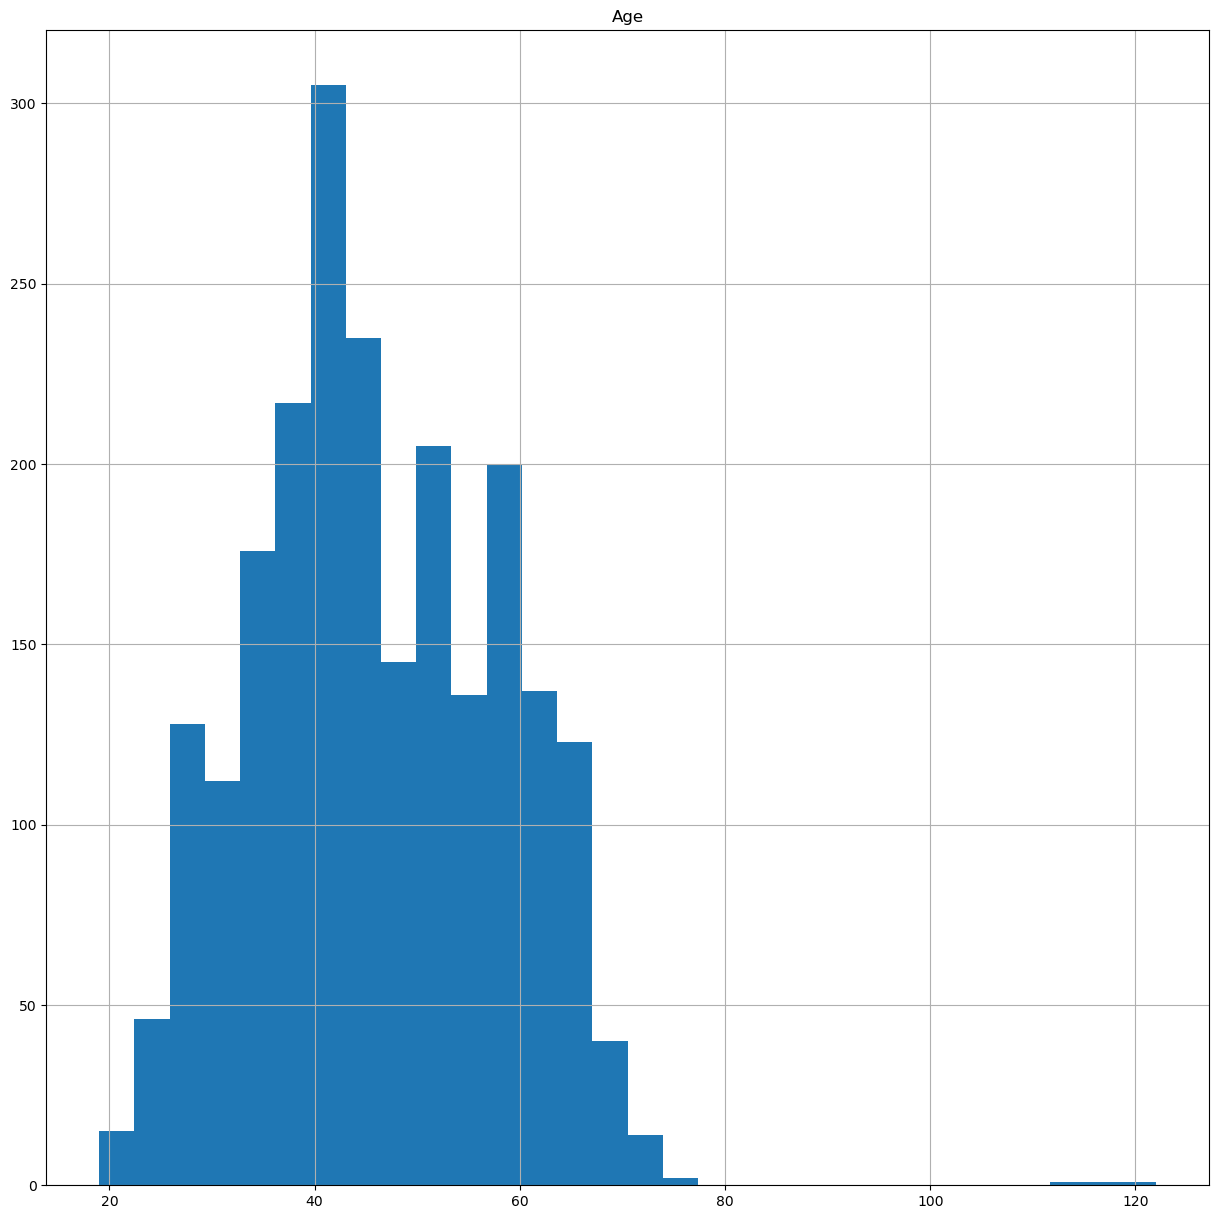

In [34]:
# Definiujemy datę odniesienia
reference_date = pd.Timestamp('2015-01-01')

# Obliczenie wieku klienta
marketing_df['Age'] = reference_date.year - marketing_df['Year_Birth']

marketing_df[['Age']].hist(bins=30, figsize=(15,15))
plt.show()

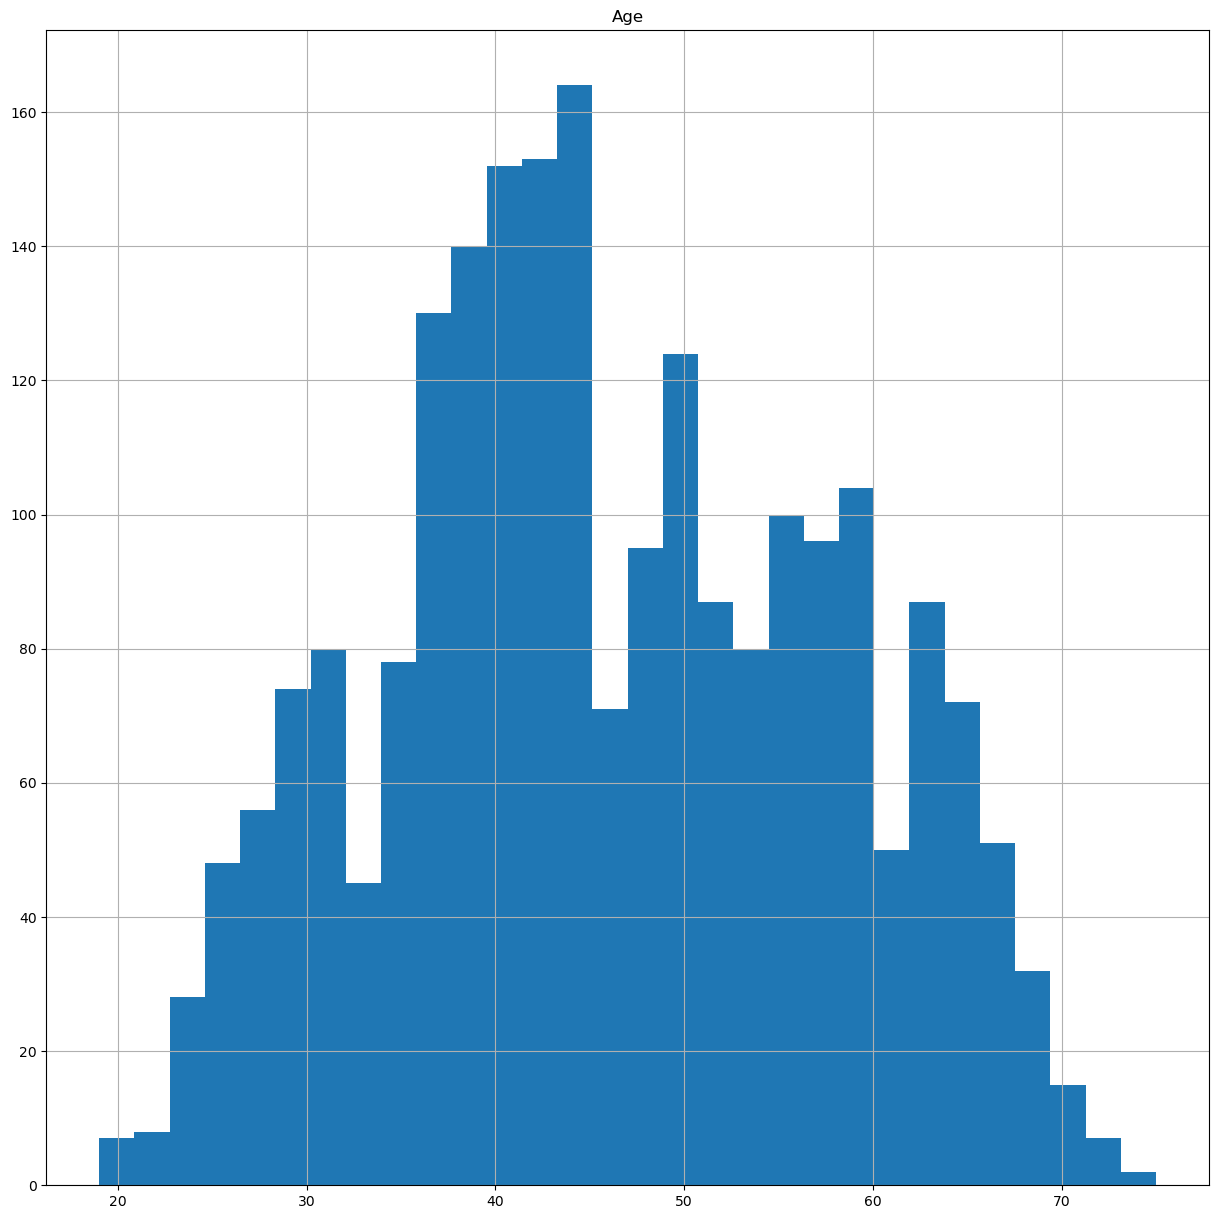

In [35]:
# Usunięcie przypadków, gdzie Age > 100
marketing_df = marketing_df[marketing_df['Age'] <= 100]

marketing_df[['Age']].hist(bins=30, figsize=(15,15))
plt.show()

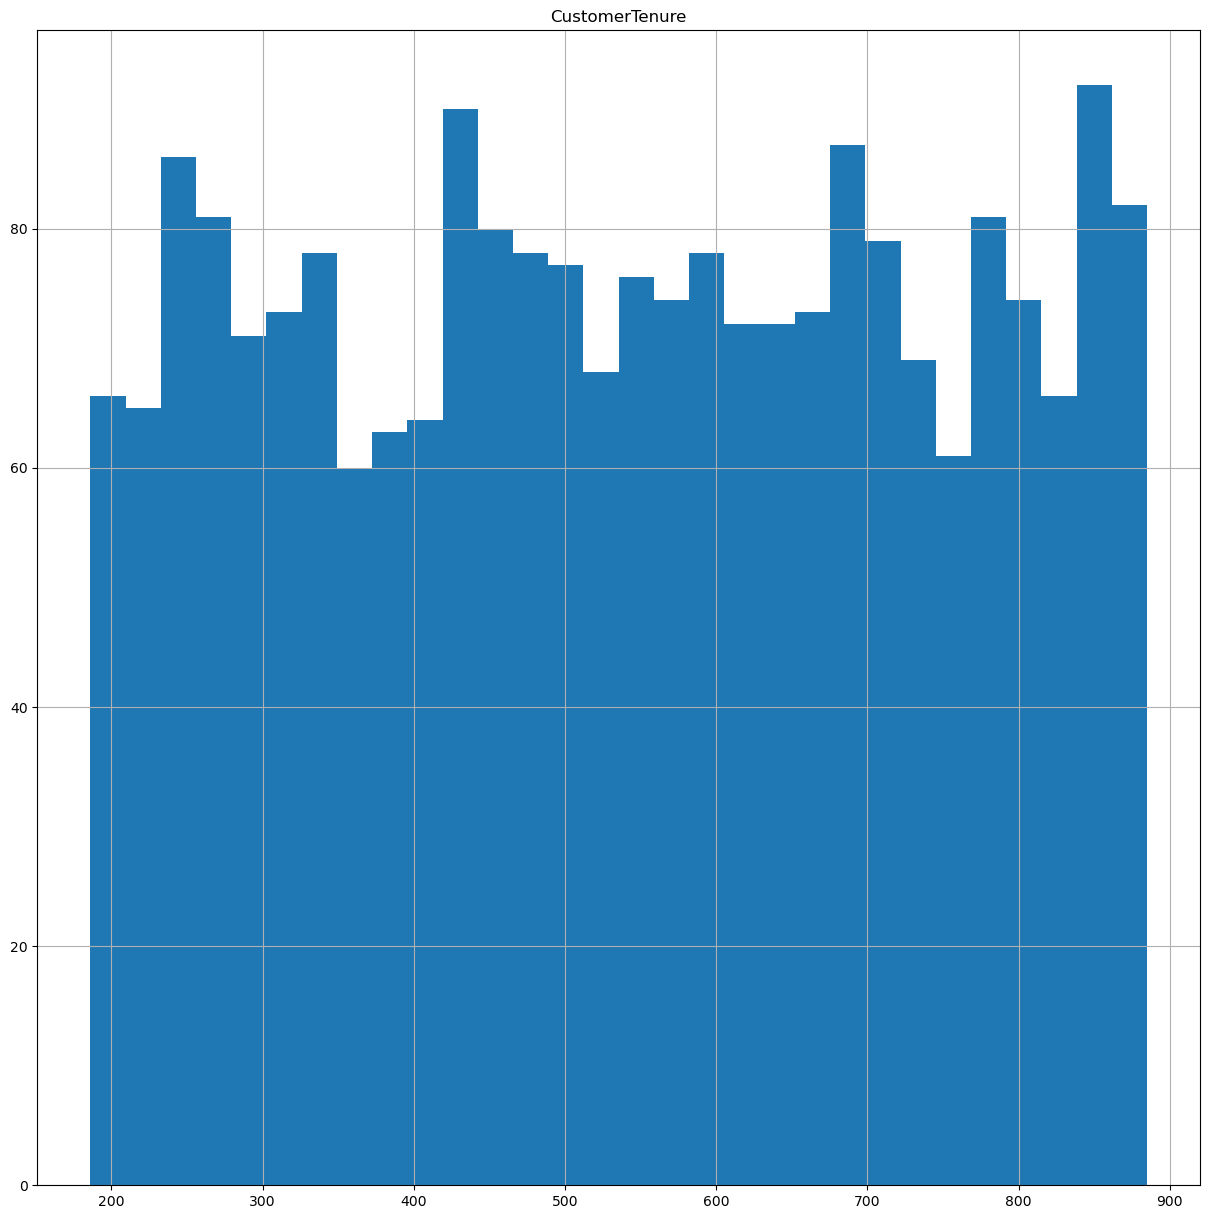

In [36]:
marketing_df['CustomerTenure'] = (reference_date - marketing_df['Dt_Customer']).dt.days

marketing_df[['CustomerTenure']].hist(bins=30, figsize=(15,15))
plt.show()

In [37]:
derrivedVars=['CustomerTenure', 'Age', 'AcceptedAnyCmp', 'IsAdvancedDegree', 'IsTogether' ]

print(derrivedVars)

['CustomerTenure', 'Age', 'AcceptedAnyCmp', 'IsAdvancedDegree', 'IsTogether']


In [38]:
predictors = num_vars + derrivedVars

print(predictors)

['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'CustomerTenure', 'Age', 'AcceptedAnyCmp', 'IsAdvancedDegree', 'IsTogether']


## Sprawdźmy powiązania pomiędzy zmiennymi

1. Korelacje między zmiennymi - za pomocą korelacji Spearmana
2. Graficzne przedstawienie za pomocą mapy ciepła
3. Powiązania pomiędzy zmiennymi za pomocą wykresu rozrzutu

In [39]:
num_vars_new = [var for var in predictors if marketing_df[var].nunique() > 2]

# Obliczanie macierzy korelacji rang Spearmana
spearman_corr_matrix = marketing_df[num_vars_new].corr(method='spearman')

spearman_corr_matrix.head(20)

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,CustomerTenure,Age
Income,1.000000,-0.558188,0.047325,0.009749,0.829626,0.578573,0.814811,0.574544,0.564791,0.504505,-0.194656,0.572140,0.789619,0.731542,-0.640295,-0.022124,0.216519
Kidhome,-0.558188,1.000000,-0.045464,0.005344,-0.580606,-0.450405,-0.551196,-0.453045,-0.438980,-0.426594,0.259220,-0.422344,-0.598132,-0.557241,0.481560,-0.049292,-0.259291
Teenhome,0.047325,-0.045464,1.000000,0.010440,0.111599,-0.199209,-0.127365,-0.229551,-0.196836,-0.020582,0.481736,0.146641,-0.043154,0.076976,0.111284,0.019649,0.386963
Recency,0.009749,0.005344,0.010440,1.000000,0.018698,0.025790,0.027736,0.013419,0.023976,0.017457,0.008946,-0.003965,0.030670,0.005609,-0.022270,0.024391,0.020109
MntWines,0.829626,-0.580606,0.111599,0.018698,1.000000,0.517400,0.823946,0.525077,0.505437,0.575247,0.057413,0.740156,0.823610,0.807129,-0.389373,0.153768,0.235318
MntFruits,0.578573,-0.450405,-0.199209,0.025790,0.517400,1.000000,0.713352,0.704424,0.692639,0.567790,-0.108494,0.471607,0.633668,0.584314,-0.442440,0.127825,0.025533
MntMeatProducts,0.814811,-0.551196,-0.127365,0.027736,0.823946,0.713352,1.000000,0.726815,0.696772,0.638679,-0.032955,0.679091,0.851609,0.780445,-0.492455,0.154400,0.114842
MntFishProducts,0.574544,-0.453045,-0.229551,0.013419,0.525077,0.704424,0.726815,1.000000,0.701628,0.564890,-0.119852,0.466506,0.657507,0.583861,-0.458697,0.131202,0.031164
MntSweetProducts,0.564791,-0.438980,-0.196836,0.023976,0.505437,0.692639,0.696772,0.701628,1.000000,0.543178,-0.105134,0.463851,0.627932,0.582062,-0.448400,0.115340,-0.002840
MntGoldProds,0.504505,-0.426594,-0.020582,0.017457,0.575247,0.567790,0.638679,0.564890,0.543178,1.000000,0.091973,0.580217,0.648418,0.541472,-0.259268,0.225742,0.076590


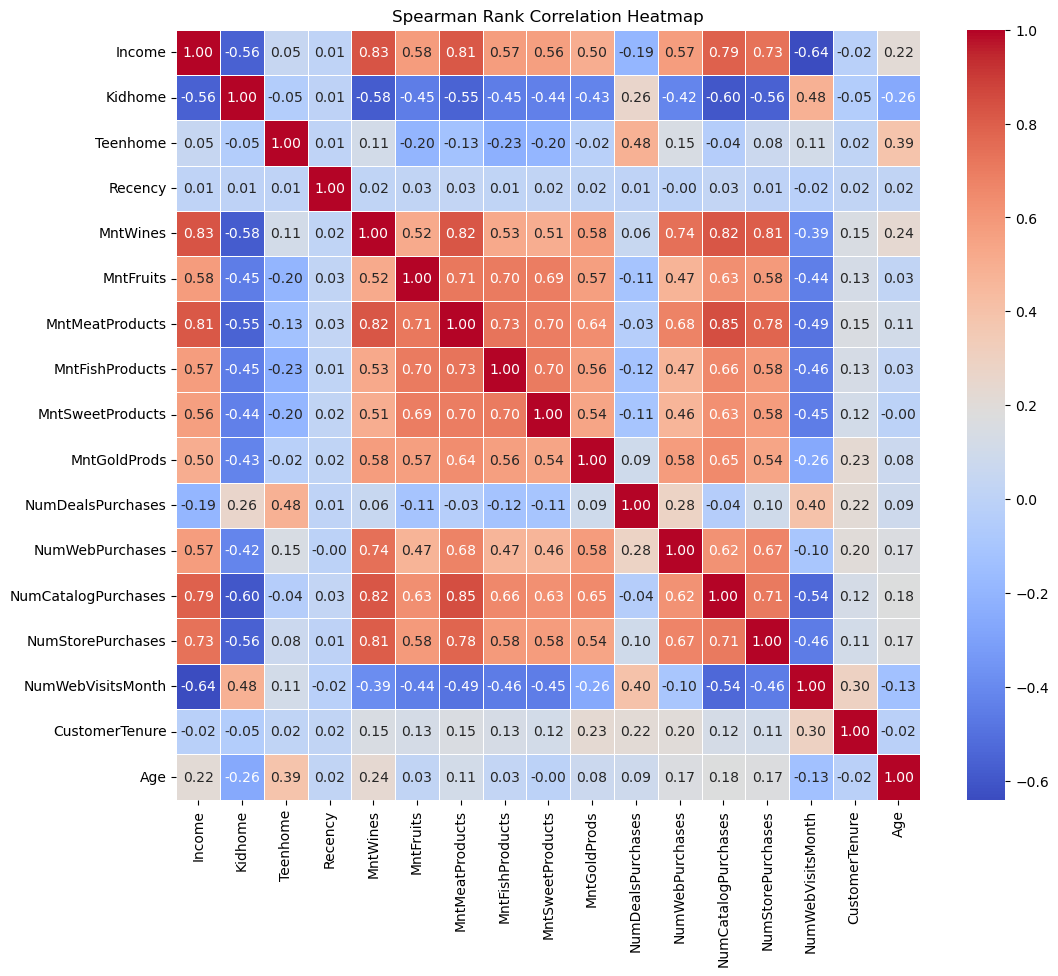

In [40]:
# Tworzenie mapy ciepła
plt.figure(figsize=(12, 10))  # Możesz dostosować wymiary
sns.heatmap(spearman_corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

# Tytuł wykresu
plt.title("Spearman Rank Correlation Heatmap")

# Wyświetlenie wykresu
plt.show()

### Analiza skupień wymaga przeskalowania danych do wspólnego zakresu
1. Wynik skalowania umieścimy w nowej ramce danych
2. Zobaczymy jak wyglądają rozkłady zmiennych po skalowaniu

In [41]:
# Skalujemy wartości predyktorów
# Przed wykonaniem skalowania wykonamy kopię ramki danych 
scaled_marketing_df = marketing_df.copy()

min_max_scaler = MinMaxScaler()
scaled_marketing_df[predictors]= min_max_scaler.fit_transform(scaled_marketing_df[predictors])

### Kolejne kroki wykonujemy samodzielnie na podstawie wcześniejszych analiz 

# Assistant
The error occurs because you're trying to create a subplot with index 17 in a 4x4 grid, which only has 16 positions available.

The issue is in this line:

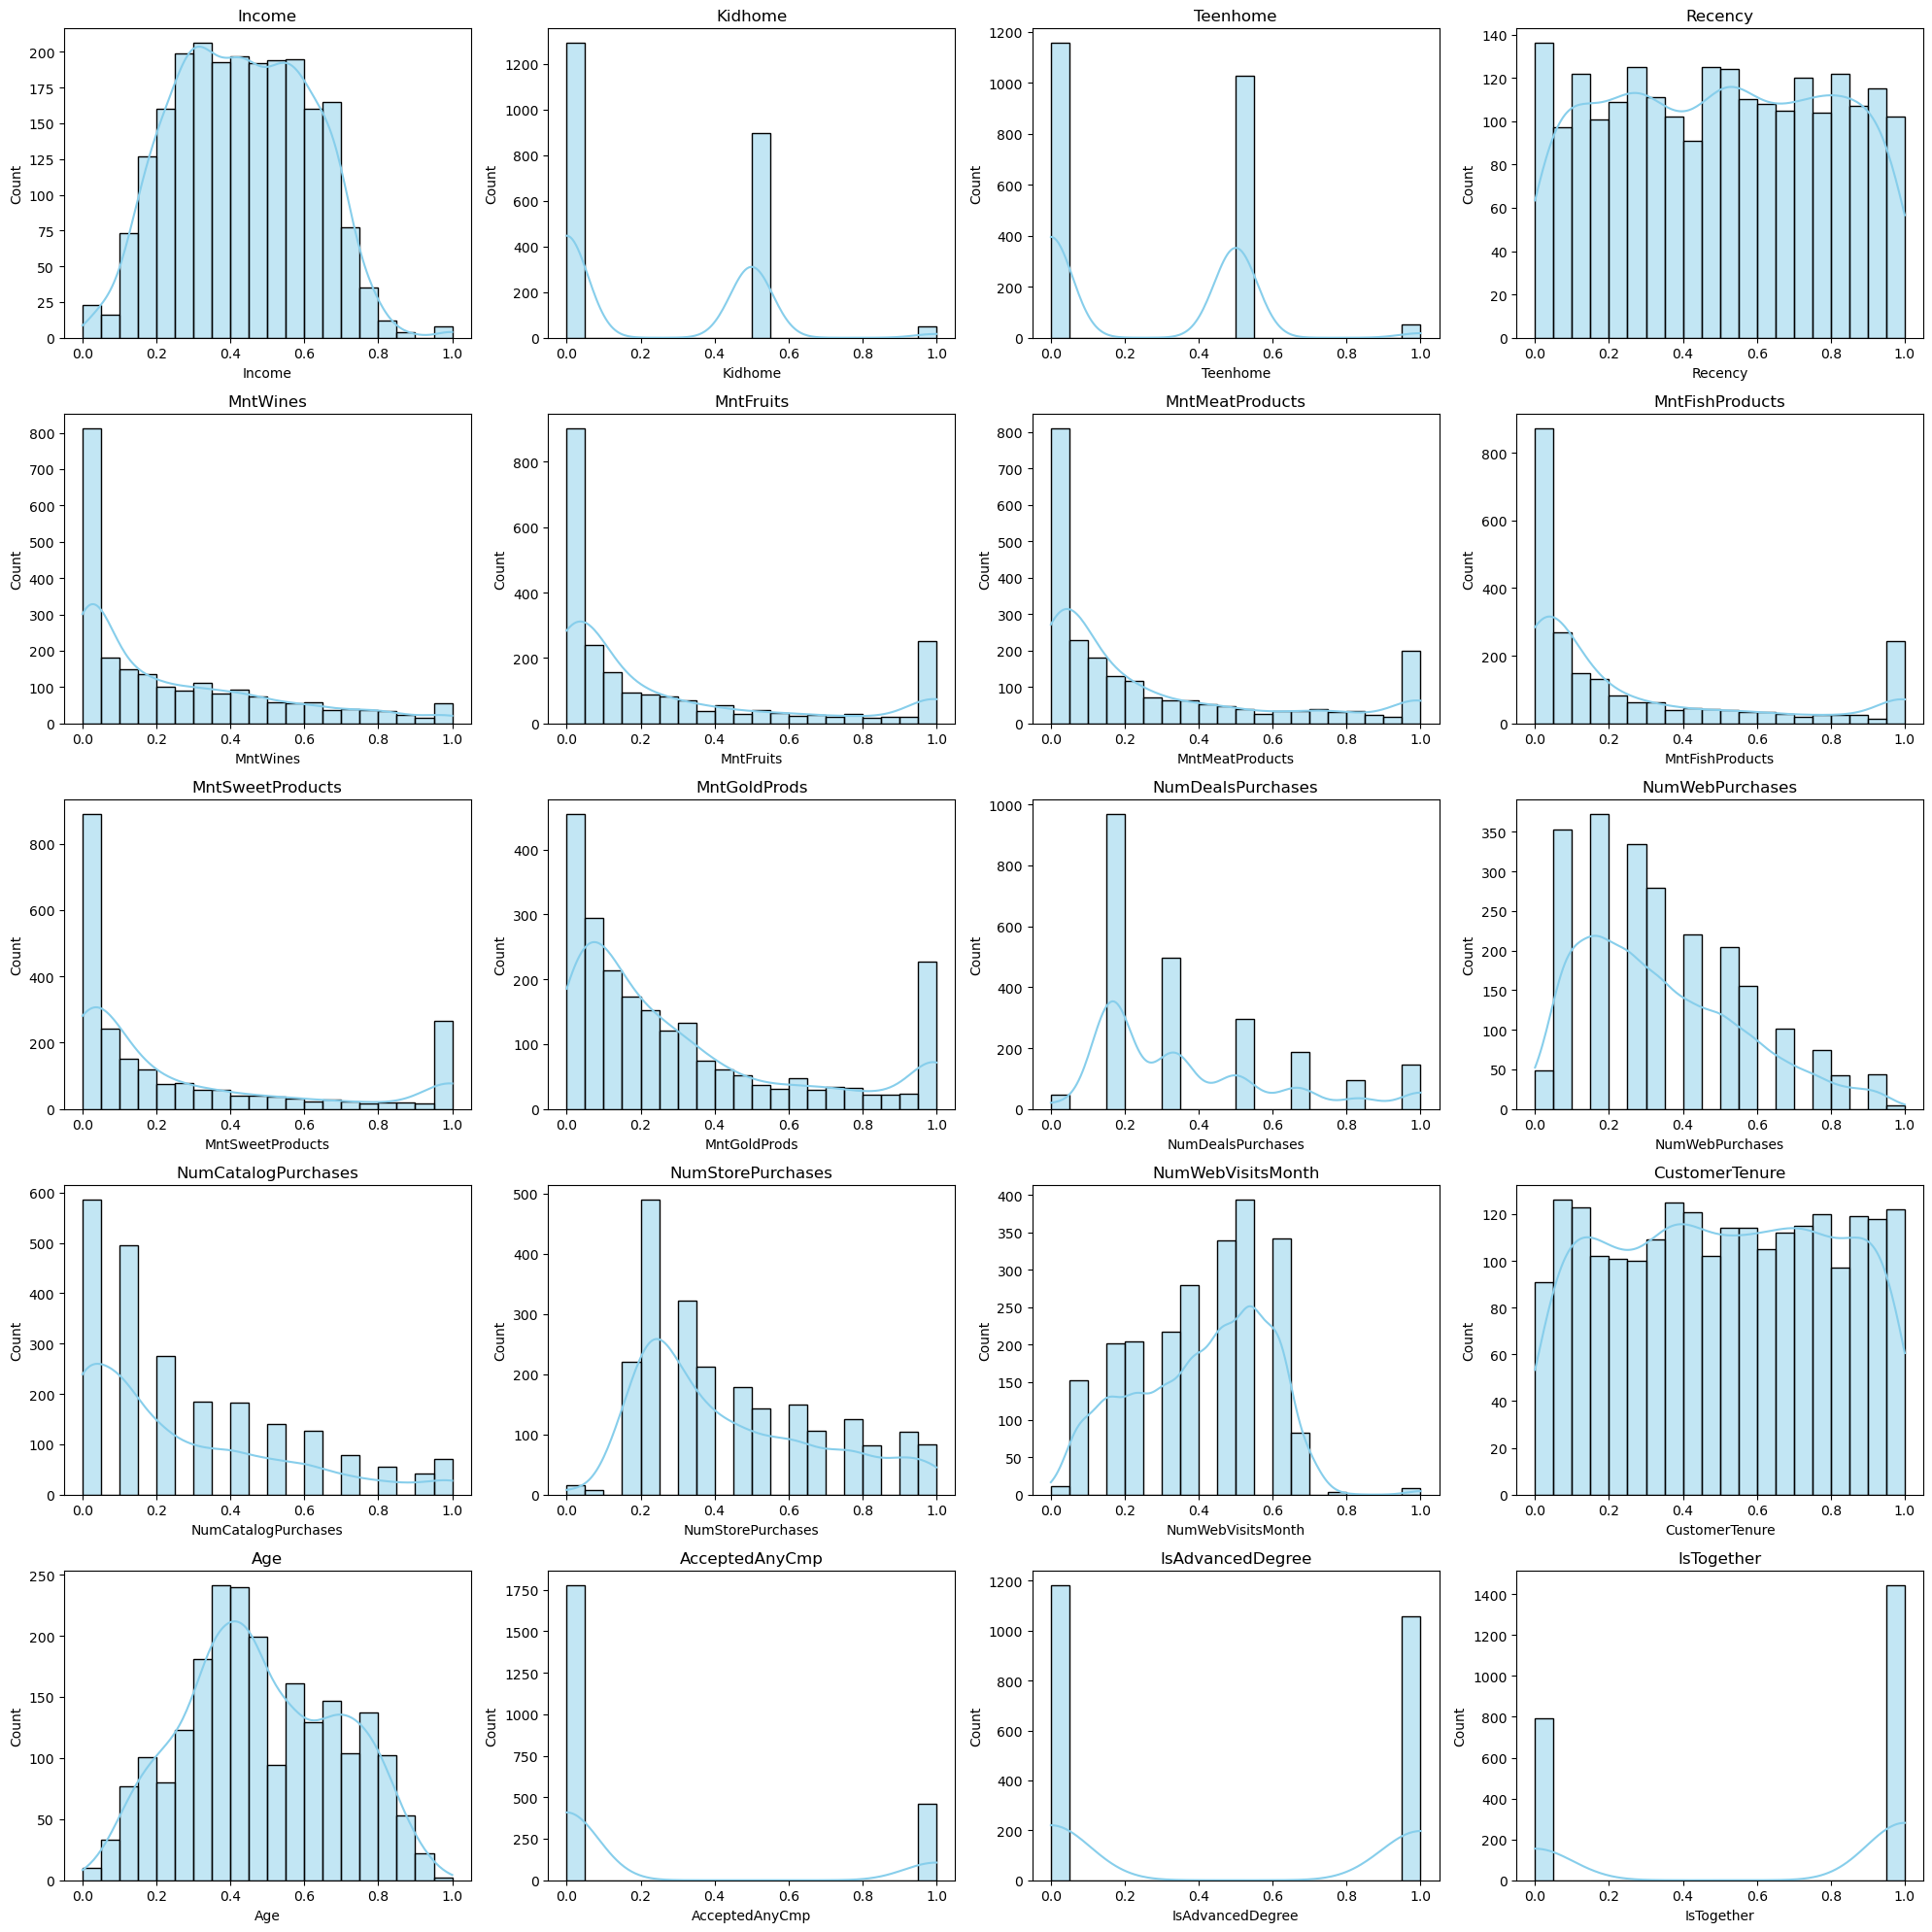

In [42]:
import math  # <- to musimy dodać!
import matplotlib.pyplot as plt
import seaborn as sns

# Liczba zmiennych
num_vars = len(predictors)

# Liczba kolumn i wierszy
cols = 4
rows = math.ceil(num_vars / cols)

plt.figure(figsize=(5 * cols, 4 * rows))  # Automatyczny rozmiar

for idx, column in enumerate(predictors):
    plt.subplot(rows, cols, idx + 1)
    sns.histplot(scaled_marketing_df[column], bins=20, kde=True, color='skyblue')
    plt.title(column)
    plt.tight_layout()

plt.show()

In [43]:
plt.show()

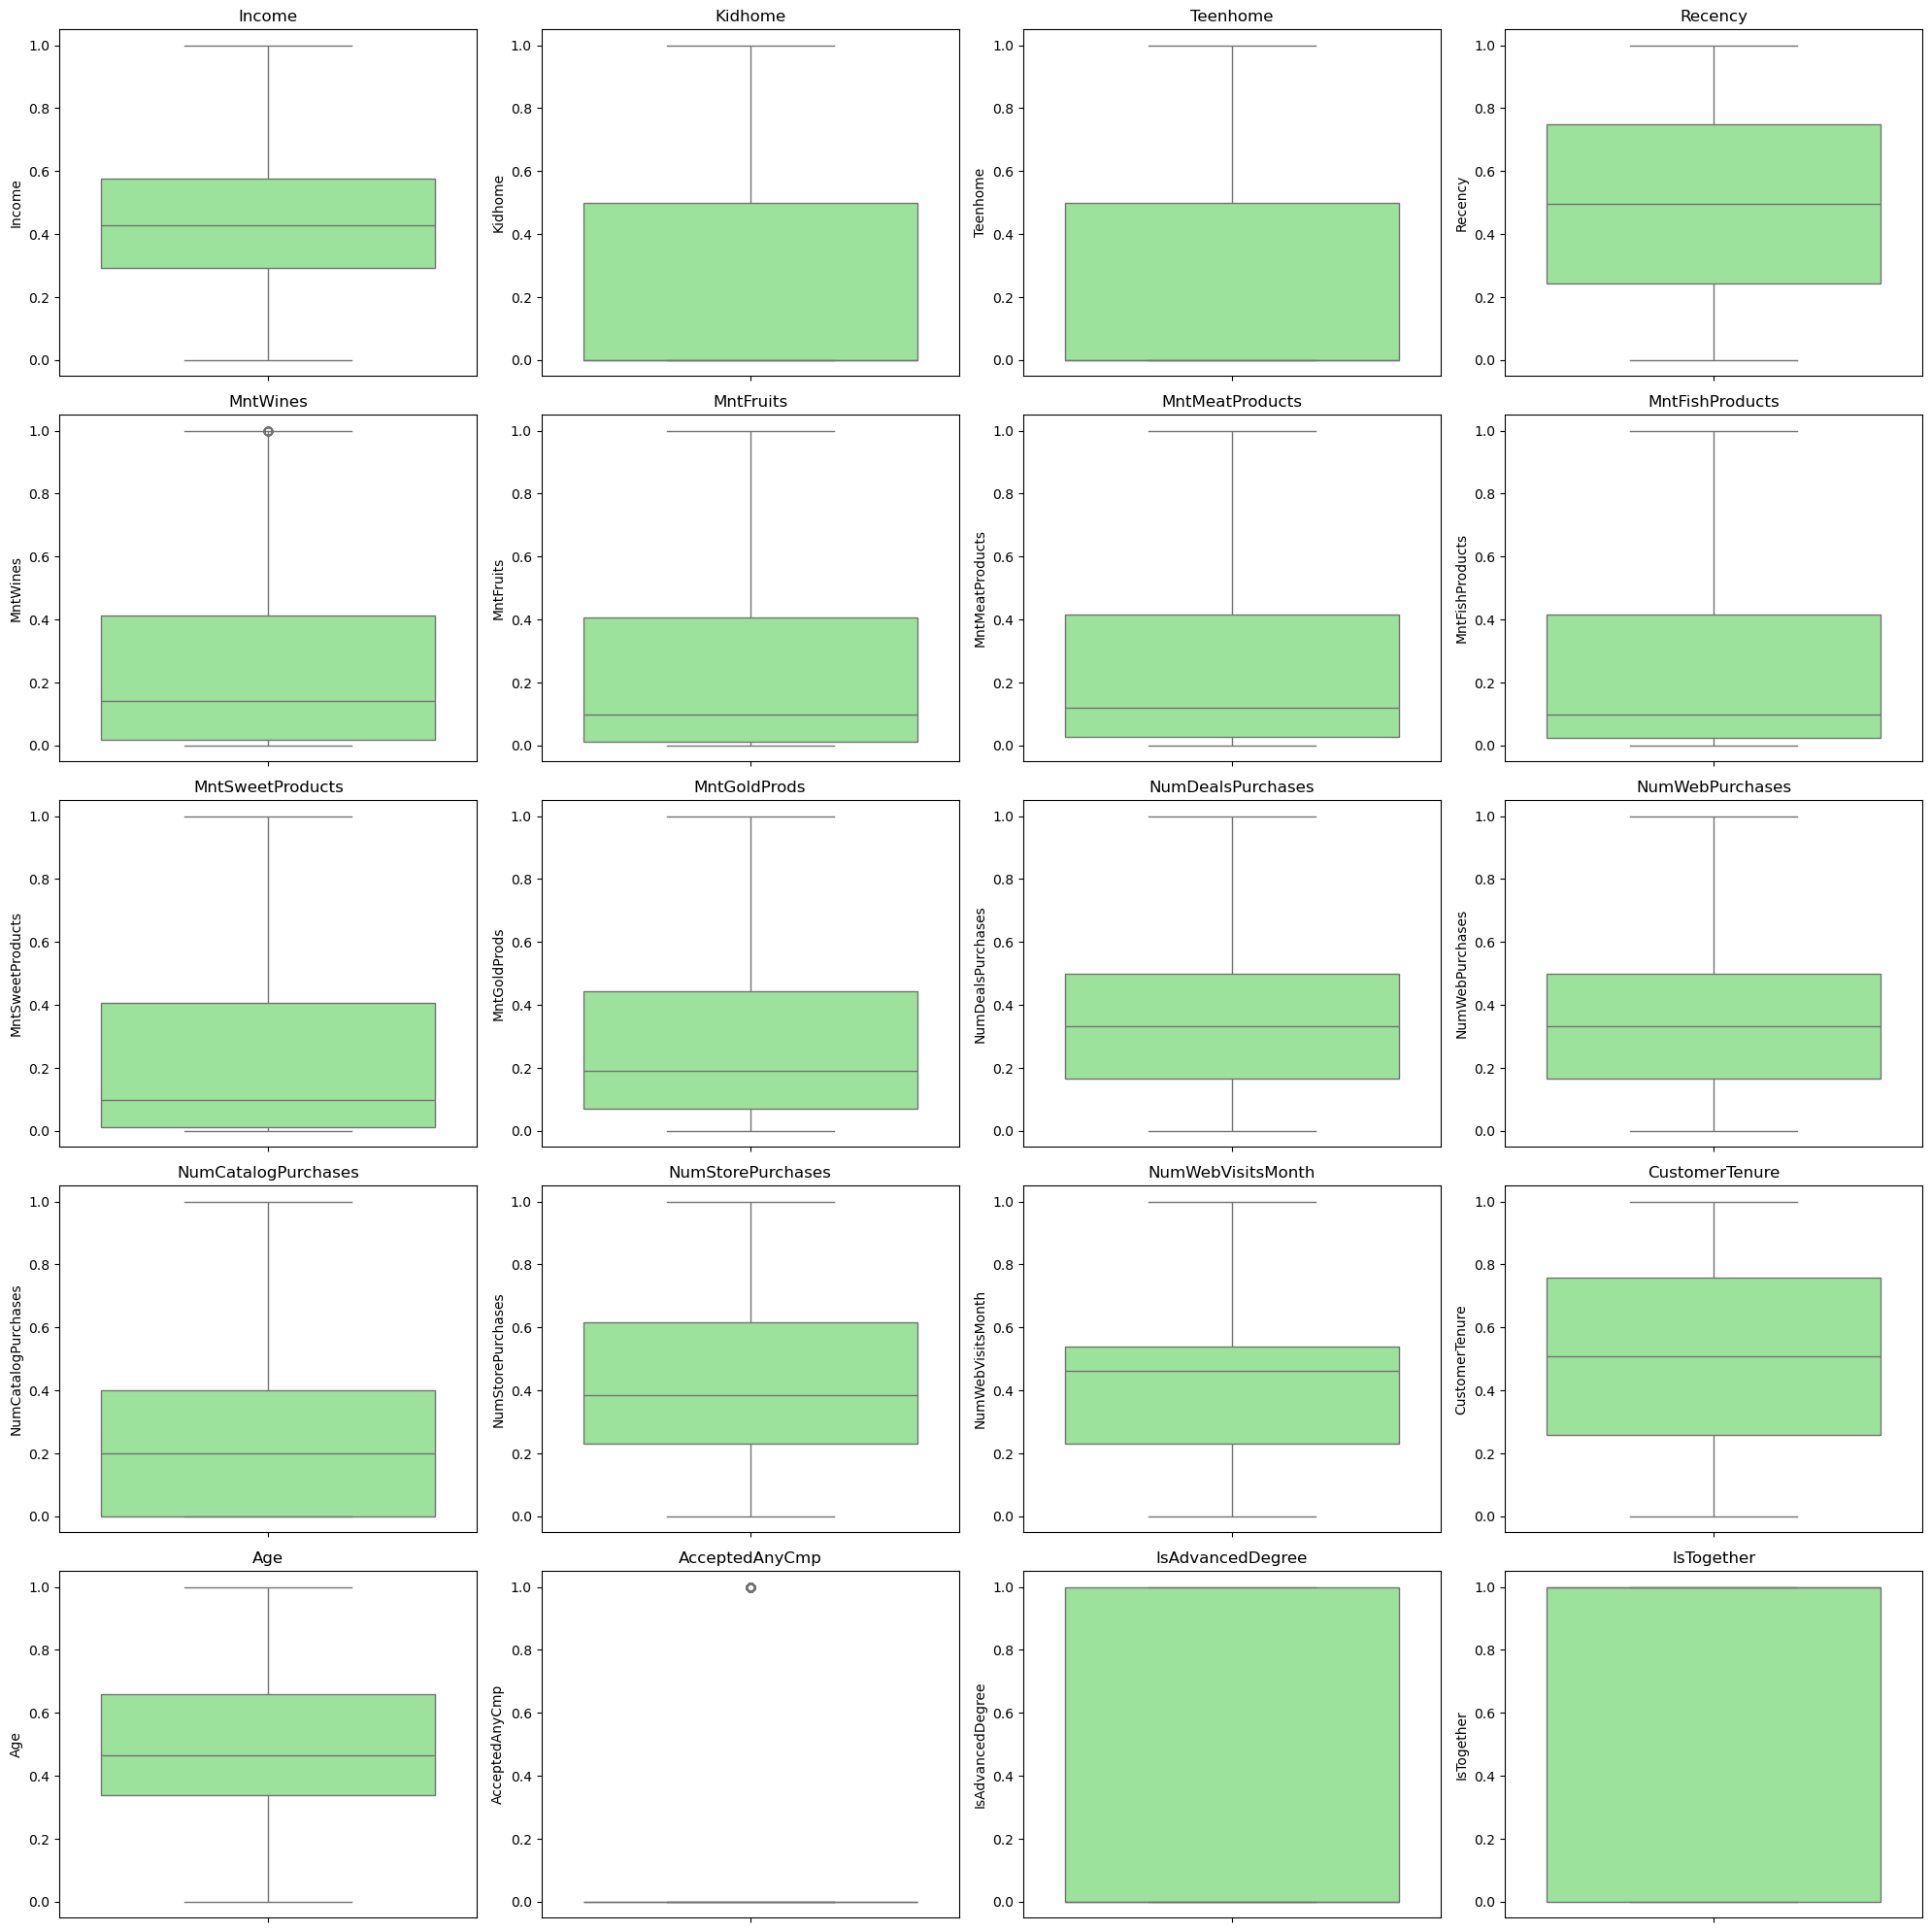

In [44]:

# Liczba zmiennych
num_vars = len(predictors)

# Liczba kolumn i wierszy
cols = 4
rows = math.ceil(num_vars / cols)

plt.figure(figsize=(5 * cols, 4 * rows))  # Dopasowany rozmiar planszy

for idx, column in enumerate(predictors):
    plt.subplot(rows, cols, idx + 1)
    sns.boxplot(y=scaled_marketing_df[column], color='lightgreen')
    plt.title(column)
    plt.tight_layout()

plt.show()

In [45]:
plt.show()

STATYSTYKI OPISOWE PO SKALOWANIU:


,count,mean,std,min,25%,50%,75%,max
Income,2236.0,0.433113,0.180651,0.0,0.291989,0.429275,0.575339,1.0
Kidhome,2236.0,0.222048,0.269230,0.0,0.000000,0.000000,0.500000,1.0
Teenhome,2236.0,0.253354,0.272305,0.0,0.000000,0.000000,0.500000,1.0
Recency,2236.0,0.496124,0.292498,0.0,0.242424,0.494949,0.747475,1.0
MntWines,2236.0,0.246730,0.270193,0.0,0.019588,0.142012,0.411549,1.0
MntFruits,2236.0,0.267563,0.336376,0.0,0.012346,0.098765,0.407407,1.0
MntMeatProducts,2236.0,0.271368,0.321398,0.0,0.028777,0.120504,0.417266,1.0
MntFishProducts,2236.0,0.266531,0.334927,0.0,0.024896,0.099585,0.414938,1.0
MntSweetProducts,2236.0,0.270942,0.340006,0.0,0.012346,0.098765,0.407407,1.0
MntGoldProds,2236.0,0.312129,0.315475,0.0,0.071146,0.189723,0.442688,1.0



ANALIZA OUTLIERÓW:


,Liczba outlierów
AcceptedAnyCmp,462
MntWines,35
Income,0
NumWebPurchases,0
IsAdvancedDegree,0
Age,0
CustomerTenure,0
NumWebVisitsMonth,0
NumStorePurchases,0
NumCatalogPurchases,0



MACIERZ KORELACJI:


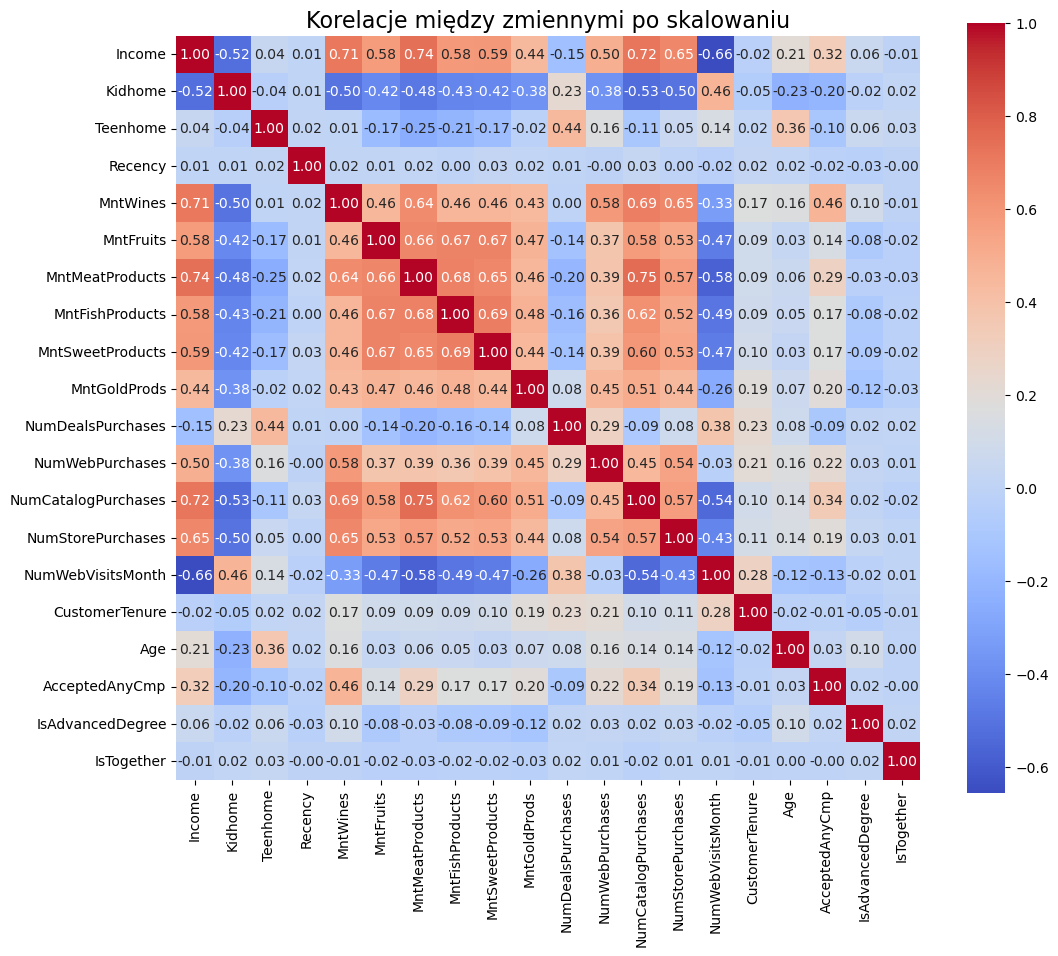

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#Co dokładnie robi ten kod:

#describe(): pokazuje średnie, min, max, kwartyle po skalowaniu (sprawdzisz, czy dane rzeczywiście są w zakresie [0,1]).
#Outliery: liczysz ile wartości w każdej zmiennej przekracza 1.5 * IQR (klasyczna reguła wykrywania odstających).
#Macierz korelacji (heatmapa): zobaczysz, które zmienne są silnie skorelowane — przyda się przy dalszej analizie skupień.

# 1. Statystyki opisowe po skalowaniu
print("STATYSTYKI OPISOWE PO SKALOWANIU:")
display(scaled_marketing_df[predictors].describe().T)

#1. Ogólna ocena skalowania

    #Zakresy wszystkich zmiennych wynoszą dokładnie od 0 do 1, czyli skalowanie MinMaxScaler zadziałało poprawnie! 
    #Średnie (mean) zmiennych są różne — co jest normalne: MinMaxScaler nie ustawia średniej na 0.5, tylko rozciąga dane w nowy zakres.
#2. Szczegółowa interpretacja zmiennych
#Zmienna	Wnioski
#Income	Średnia (0.43) i mediana (0.43) są zbliżone — rozkład dosyć symetryczny.
#Kidhome, Teenhome	Dużo zer, mediana = 0 → większość klientów nie ma dzieci ani nastolatków w domu.
#Recency	Rozkład przesunięty lekko w stronę mniejszych wartości (nowsze zakupy są częstsze).
#MntWines, MntFruits, MntMeatProducts, MntFishProducts, MntSweetProducts, MntGoldProds	Średnie i mediany poniżej 0.5 → małe wydatki są bardziej popularne, kilka osób mocno zwiększa średnią (outliery).
#NumDealsPurchases, NumWebPurchases, NumCatalogPurchases, NumStorePurchases	Średnie blisko 0.3-0.4 — umiarkowana aktywność zakupowa klientów.
#NumWebVisitsMonth	Średnia 0.41, mediana 0.46 — lekko prawostronny rozkład, niektórzy odwiedzają stronę wyjątkowo często.
#CustomerTenure (czas związania z firmą)	Średnia i mediana blisko 0.5 — rozkład dość symetryczny, choć sporo starszych klientów.
#Age	Rozkład przesunięty w stronę wyższych wartości (średnia 0.48, mediana 0.46) — większość klientów to osoby w średnim/wyższym wieku.
#AcceptedCmp1, AcceptedCmp2, AcceptedCmp3, AcceptedCmp4, AcceptedCmp5	Dużo zer — większość klientów nie brała udziału w kampaniach marketingowych.
#IsAdvancedDegree	Średnia 0.47 → około połowy klientów ma wykształcenie wyższe.
#IsTogether	Średnia 0.64 → większość klientów mieszka w związku lub w rodzinie.

# 2. Analiza outlierów za pomocą reguły 1.5*IQR
print("\nANALIZA OUTLIERÓW:")

outlier_summary = {}

for col in predictors:
    Q1 = scaled_marketing_df[col].quantile(0.25)
    Q3 = scaled_marketing_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = scaled_marketing_df[(scaled_marketing_df[col] < lower_bound) | (scaled_marketing_df[col] > upper_bound)]
    outlier_summary[col] = len(outliers)

outlier_df = pd.DataFrame.from_dict(outlier_summary, orient='index', columns=['Liczba outlierów'])
outlier_df = outlier_df.sort_values('Liczba outlierów', ascending=False)

display(outlier_df)

# 3. Wizualizacja korelacji między zmiennymi
print("\nMACIERZ KORELACJI:")

plt.figure(figsize=(12, 10))
sns.heatmap(scaled_marketing_df[predictors].corr(), annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title("Korelacje między zmiennymi po skalowaniu", fontsize=16)
plt.show()

In [47]:
# | Próg korelacji | Znaczenie w praktyce                             | Typowe zalecenie           |
# | **> 0.9**      | Prawie duplikaty                                 | **Zawsze usuń jedną**      |
# | **0.8 – 0.9**  | Silna współliniowość (problematyczna w regresji) | **Zwykle usuwa się jedną** |
# | **0.7 – 0.8**  | Silna korelacja, ale nie zawsze problematyczna   | **Czasem warto usunąć**    |
# | **< 0.7**      | Umiarkowana lub niska korelacja                  | **Zazwyczaj zostawiasz**   |
# MntWines ↔ MntMeatProducts: korelacja ≈ 0.75 - zdecydowałem się nie usuwać tej zmiennych

In [48]:
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt
import numpy as np

def plot_dendrogram(scaled_marketing_df, predictors, method='ward', figsize=(12, 8)):
    """
    Rysuje dendrogram dla hierarchicznego klastrowania.

    Parametry:
    - scaled_marketing_df: DataFrame zawierający dane skalowane (bez braków)
    - predictors: lista zmiennych liczbowych do klastrowania
    - method: metoda łączenia ('ward', 'single', 'complete', 'average')
    - figsize: rozmiar wykresu dendrogramu
    """
    # Przygotowanie danych
    X = scaled_marketing_df[predictors]

    # Tworzenie macierzy połączeń
    linkage_matrix = sch.linkage(X, method=method)

    # Rysowanie dendrogramu
    plt.figure(figsize=figsize)
    sch.dendrogram(linkage_matrix, orientation='top', distance_sort='ascending', show_leaf_counts=True)

    plt.title(f'Dendrogram (metoda: {method})', fontsize=14)
    plt.xlabel("Obserwacje")
    plt.ylabel("Odległość")
    plt.tight_layout()
    plt.show()


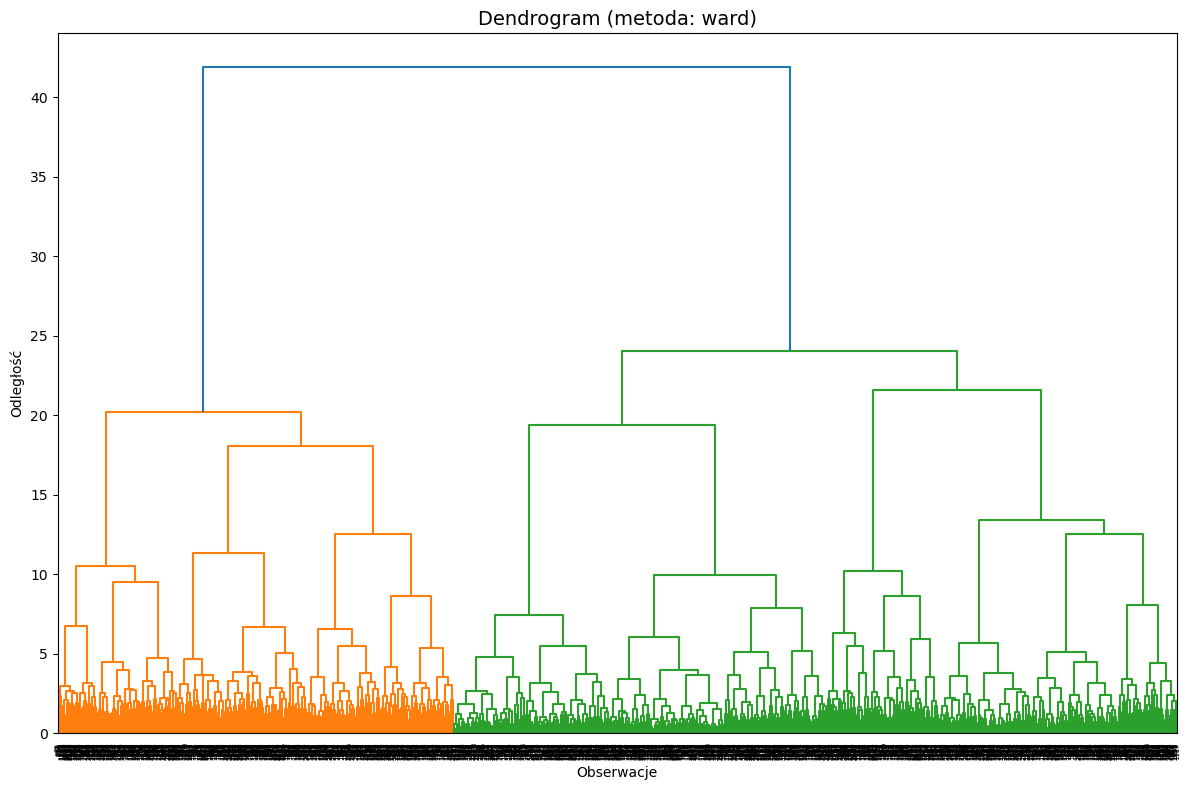

In [49]:
plot_dendrogram(scaled_marketing_df, predictors)


In [50]:


from scipy.cluster.hierarchy import linkage, fcluster

# Obliczanie macierzy połączeń
X = scaled_marketing_df[predictors]
linkage_matrix = linkage(X, method='ward')

# Przypisanie etykiet klastrów (do 19 grup)
labels = fcluster(linkage_matrix, t=19, criterion='maxclust')

# Dodanie kolumny z numerem klastra
scaled_marketing_df['Cluster'] = labels

scaled_marketing_df[['Cluster'] + predictors].head()


,Cluster,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,CustomerTenure,Age,AcceptedAnyCmp,IsAdvancedDegree,IsTogether
0,4,0.487691,0.0,0.0,0.585859,0.518262,1.000000,0.982014,1.000000,1.000000,0.695652,0.500000,0.666667,1.0,0.307692,0.538462,0.948498,0.696429,0.0,0.0,0.0
1,16,0.385722,0.5,0.5,0.383838,0.008978,0.012346,0.010791,0.016598,0.012346,0.047431,0.333333,0.083333,0.1,0.153846,0.384615,0.161660,0.750000,0.0,0.0,0.0
2,5,0.604192,0.0,0.0,0.262626,0.347684,0.604938,0.228417,0.921162,0.259259,0.332016,0.166667,0.666667,0.2,0.769231,0.307692,0.446352,0.553571,0.0,0.0,1.0
3,10,0.215418,0.5,0.0,0.262626,0.008978,0.049383,0.035971,0.082988,0.037037,0.039526,0.333333,0.166667,0.0,0.307692,0.461538,0.198856,0.214286,0.0,0.0,1.0
4,9,0.489031,0.5,0.0,0.949495,0.141196,0.530864,0.212230,0.381743,0.333333,0.118577,0.833333,0.416667,0.3,0.461538,0.384615,0.230329,0.267857,0.0,1.0,1.0


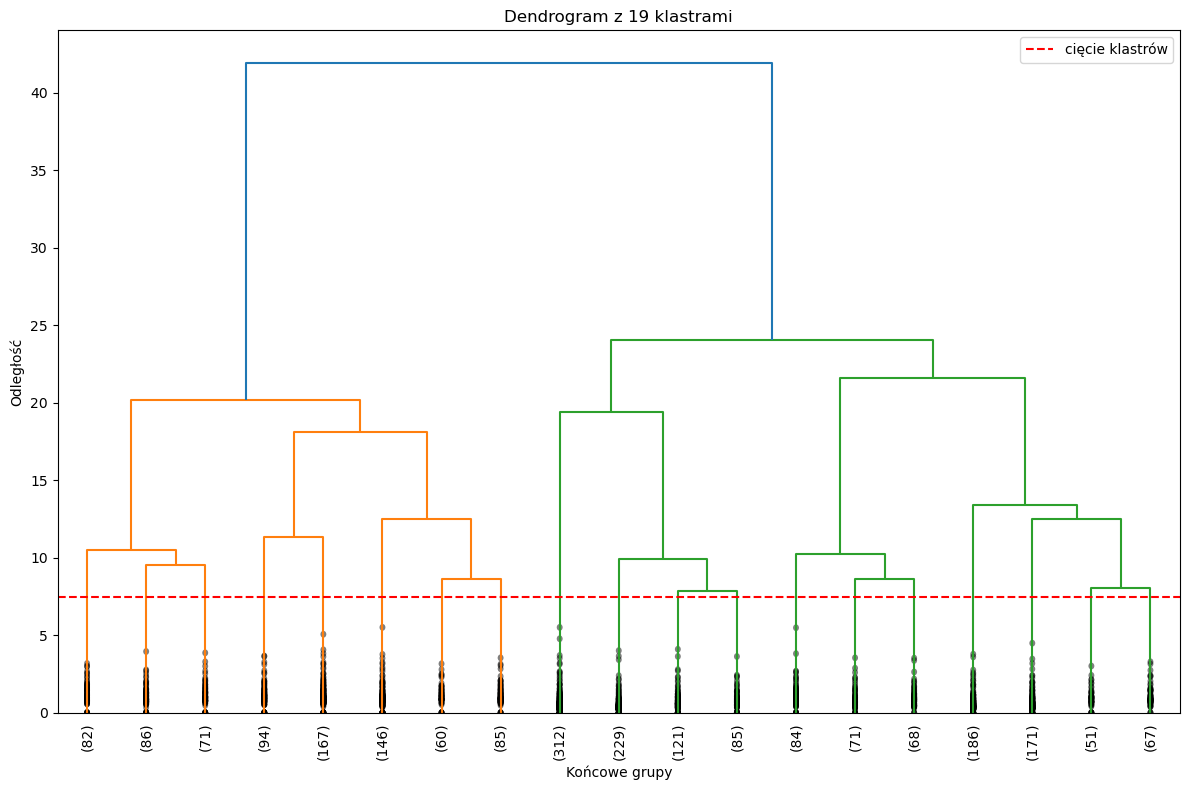

In [51]:
#Rysowanie dendrogramu z linią cięcia (dla 19 klastrów)
plt.figure(figsize=(12, 8))
sch.dendrogram(
    linkage_matrix,
    color_threshold=None,       # wszystkie gałęzie w jednym kolorze, możesz zmienić
    truncate_mode='lastp',      # pokazujemy tylko ostatnie p klastrów
    p=19,                       # liczba końcowych klastrów (gałęzi)
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)

plt.axhline(y=linkage_matrix[-19, 2], color='red', linestyle='--', label='cięcie klastrów')
plt.title("Dendrogram z 19 klastrami")
plt.xlabel("Końcowe grupy")
plt.ylabel("Odległość")
plt.legend()
plt.tight_layout()
plt.show()



In [52]:
# W przypadku tej analizy jedną z metod określenia liczby skupień jest analiza wykresu przebiegu aglomeracji i identyfikacja
# pierwszego "wyraźnego" wzrostu liczby skupień


In [53]:

def plot_agglomeration_process(scaled_marketing_df, predictors, method='ward'):
    """
    Rysuje wykres przedstawiający przebieg aglomeracji (odległość vs krok klastrowania).
    
    Parametry:
    - scaled_marketing_df: DataFrame z danymi (skalowanymi, bez braków)
    - predictors: lista zmiennych liczbowych do klastrowania
    - method: metoda łączenia ('ward', 'single', 'complete', 'average')
    """
    # Macierz połączeń
    X = scaled_marketing_df[predictors]
    linked = sch.linkage(X, method=method)

    # Numer kroku i odpowiadająca odległość
    steps = np.arange(1, len(linked) + 1)
    distances = linked[:, 2]

    # Wykres
    plt.figure(figsize=(10, 6))
    plt.plot(steps, distances, marker='o', linestyle='-', color='b', alpha=0.7, label='Odległość wiązania')

    plt.xlabel("Krok")
    plt.ylabel("Odległość wiązania")
    plt.title(f"Przebieg aglomeracji ({method})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    


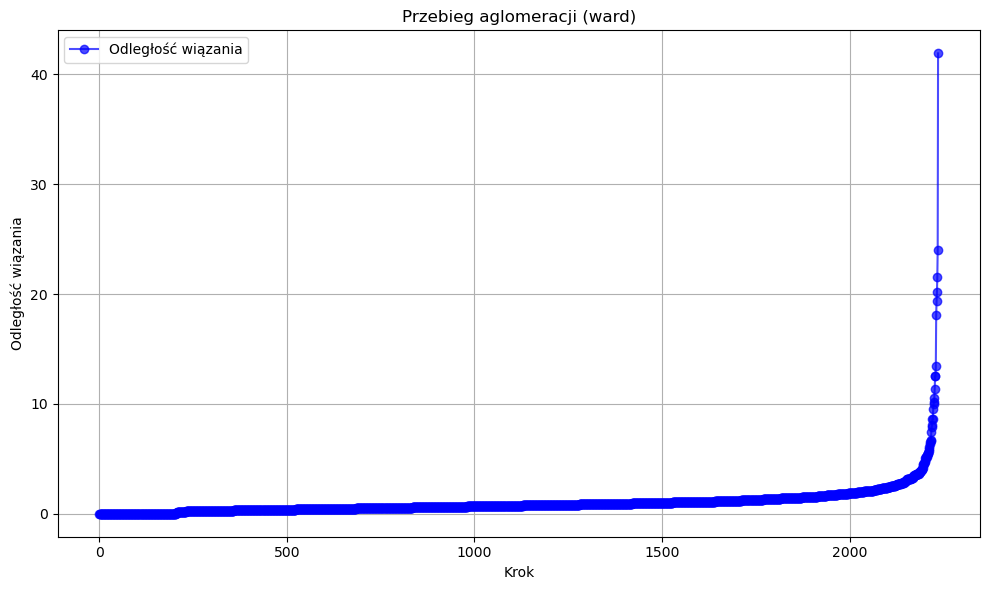

In [54]:
plot_agglomeration_process(scaled_marketing_df, predictors)

In [55]:





def plot_agglomeration_process(scaled_marketing_df, predictors, method='ward', highlight_jump=True):
    """
    Rysuje wykres aglomeracji: odległość wiązania vs krok.
    
    Parametry:
    - scaled_marketing_df: DataFrame z danymi skalowanymi
    - predictors: lista zmiennych do klastrowania
    - method: metoda łączenia klastrów
    - highlight_jump: czy zaznaczyć największy skok odległości
    """
    # 1. Macierz połączeń
    X = scaled_marketing_df[predictors]
    linked = sch.linkage(X, method=method)

    # 2. Przygotuj dane do wykresu
    steps = np.arange(1, len(linked) + 1)
    distances = linked[:, 2]

    # 3. Znajdź największy skok między kolejnymi połączeniami
    if highlight_jump:
        diffs = np.diff(distances)
        max_idx = np.argmax(diffs)
        jump_step = steps[max_idx + 1]
        jump_value = distances[max_idx + 1]

    # 4. Wykres
    plt.figure(figsize=(10, 6))
    plt.plot(steps, distances, marker='o', linestyle='-', color='blue', alpha=0.7, label='Odległość wiązania')

    if highlight_jump:
        plt.axvline(x=jump_step, color='red', linestyle='--', label=f'Max skok: krok {jump_step}')
        plt.axhline(y=jump_value, color='red', linestyle='--', alpha=0.4)

    plt.xlabel("Krok")
    plt.ylabel("Odległość wiązania")
    plt.title(f"Przebieg aglomeracji ({method})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return jump_value if highlight_jump else None




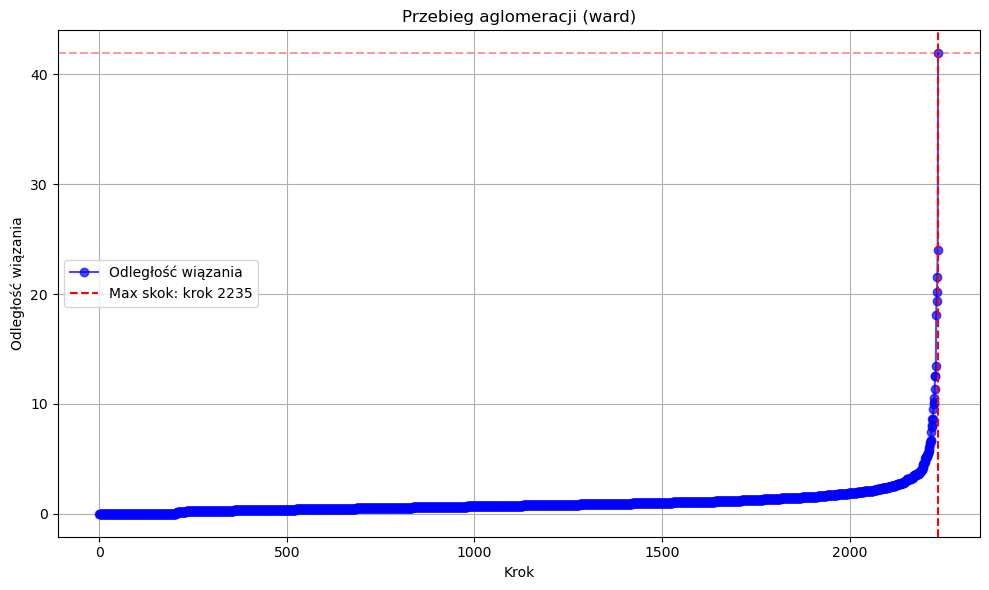

41.923489339206085

In [56]:
plot_agglomeration_process(
    scaled_marketing_df=scaled_marketing_df,
    predictors=predictors,
    method='ward'  # lub 'complete', 'average', 'single'
)



In [57]:
#Przykładowy kod dla metody aglomeracyjnej
from sklearn.cluster import AgglomerativeClustering

# Liczba klastrów
n_clusters = 4

agglo_model = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')

# Dopasowanie modelu i przypisanie klas
agglo_model_classes = agglo_model.fit_predict(scaled_marketing_df[predictors])

# Zapis predykcji do DataFrame
marketing_df['predicted_class'] = agglo_model_classes
scaled_marketing_df['predicted_class'] = agglo_model_classes


In [58]:
# Wyświetl pierwszych 10 rekordów
marketing_df.head(10) 

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,IsAdvancedDegree,IsTogether,TotalAcceptedCmp,AcceptedAnyCmp,Age,CustomerTenure,predicted_class
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635.0,81,546,120.5,81,88.0,3,8,10,4,7,0,0,0,0,0,0,1,0,0,0,0,58,849,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11.0,1,6,2.0,1,6.0,2,1,1,2,5,0,0,0,0,0,0,0,0,0,0,0,61,299,1
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426.0,49,127,111.0,21,42.0,1,8,2,10,4,0,0,0,0,0,0,0,0,1,0,0,50,498,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11.0,4,20,10.0,3,5.0,2,2,0,4,6,0,0,0,0,0,0,0,0,1,0,0,31,325,2
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173.0,43,118,46.0,27,15.0,5,5,3,6,5,0,0,0,0,0,0,0,1,1,0,0,34,347,2
5,7446,1967,Master,Together,62513.0,0,1,2013-09-09,16,520.0,42,98,0.0,42,14.0,2,6,4,10,6,0,0,0,0,0,0,0,1,1,0,0,48,479,0
6,965,1971,Graduation,Divorced,55635.0,0,1,2012-11-13,34,235.0,65,164,50.0,49,27.0,4,7,3,7,6,0,0,0,0,0,0,0,0,0,0,0,44,779,1
7,6177,1985,PhD,Married,33454.0,1,0,2013-05-08,32,76.0,10,56,3.0,1,23.0,2,4,0,4,8,0,0,0,0,0,0,0,1,1,0,0,30,603,2
8,4855,1974,PhD,Together,30351.0,1,0,2013-06-06,19,14.0,0,24,3.0,3,2.0,1,3,0,2,9,0,0,0,0,0,0,1,1,1,0,0,41,574,2
9,5899,1950,PhD,Together,5648.0,1,1,2014-03-13,68,28.0,0,6,1.0,1,13.0,1,1,0,0,13,1,0,0,0,0,0,0,1,1,1,1,65,294,3


In [59]:
# Wyświetl pierwszych 10 rekordów
scaled_marketing_df.head(10) 

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,IsAdvancedDegree,IsTogether,TotalAcceptedCmp,AcceptedAnyCmp,Age,CustomerTenure,Cluster,predicted_class
0,5524,1957,Graduation,Single,0.487691,0.0,0.0,2012-09-04,0.585859,0.518262,1.000000,0.982014,1.000000,1.000000,0.695652,0.500000,0.666667,1.0,0.307692,0.538462,0,0,0,0,0,0,1,0.0,0.0,0,0.0,0.696429,0.948498,4,0
1,2174,1954,Graduation,Single,0.385722,0.5,0.5,2014-03-08,0.383838,0.008978,0.012346,0.010791,0.016598,0.012346,0.047431,0.333333,0.083333,0.1,0.153846,0.384615,0,0,0,0,0,0,0,0.0,0.0,0,0.0,0.750000,0.161660,16,1
2,4141,1965,Graduation,Together,0.604192,0.0,0.0,2013-08-21,0.262626,0.347684,0.604938,0.228417,0.921162,0.259259,0.332016,0.166667,0.666667,0.2,0.769231,0.307692,0,0,0,0,0,0,0,0.0,1.0,0,0.0,0.553571,0.446352,5,0
3,6182,1984,Graduation,Together,0.215418,0.5,0.0,2014-02-10,0.262626,0.008978,0.049383,0.035971,0.082988,0.037037,0.039526,0.333333,0.166667,0.0,0.307692,0.461538,0,0,0,0,0,0,0,0.0,1.0,0,0.0,0.214286,0.198856,10,2
4,5324,1981,PhD,Married,0.489031,0.5,0.0,2014-01-19,0.949495,0.141196,0.530864,0.212230,0.381743,0.333333,0.118577,0.833333,0.416667,0.3,0.461538,0.384615,0,0,0,0,0,0,0,1.0,1.0,0,0.0,0.267857,0.230329,9,2
5,7446,1967,Master,Together,0.525516,0.0,0.5,2013-09-09,0.161616,0.424403,0.518519,0.176259,0.000000,0.518519,0.110672,0.333333,0.500000,0.4,0.769231,0.461538,0,0,0,0,0,0,0,1.0,1.0,0,0.0,0.517857,0.419170,6,0
6,965,1971,Graduation,Divorced,0.466050,0.0,0.5,2012-11-13,0.343434,0.191798,0.802469,0.294964,0.414938,0.604938,0.213439,0.666667,0.583333,0.3,0.538462,0.461538,0,0,0,0,0,0,0,0.0,0.0,0,0.0,0.446429,0.848355,19,1
7,6177,1985,PhD,Married,0.274278,0.5,0.0,2013-05-08,0.323232,0.062028,0.123457,0.100719,0.024896,0.012346,0.181818,0.333333,0.333333,0.0,0.307692,0.615385,0,0,0,0,0,0,0,1.0,1.0,0,0.0,0.196429,0.596567,9,2
8,4855,1974,PhD,Together,0.247451,0.5,0.0,2013-06-06,0.191919,0.011426,0.000000,0.043165,0.024896,0.037037,0.015810,0.166667,0.250000,0.0,0.153846,0.692308,0,0,0,0,0,0,1,1.0,1.0,0,0.0,0.392857,0.555079,9,2
9,5899,1950,PhD,Together,0.033874,0.5,0.5,2014-03-13,0.686869,0.022852,0.000000,0.010791,0.008299,0.012346,0.102767,0.166667,0.083333,0.0,0.000000,1.000000,1,0,0,0,0,0,0,1.0,1.0,1,1.0,0.821429,0.154506,14,3


In [60]:
# Chcemy teraz zrozumieć uzyskane wyniki
#     Oceniamy liczbę elementów w poszczególnych skupieniach (małe liczności mogą świadczyć o błędnym modelu)
#     Badamy średnie wartości zmiennych w skupieniach (brak zróżnicowania zmiennych może być podstawą do jej eliminacji)
#     Prezentujemy śerednie wartości wyskalowanych zmiennych na wykresie


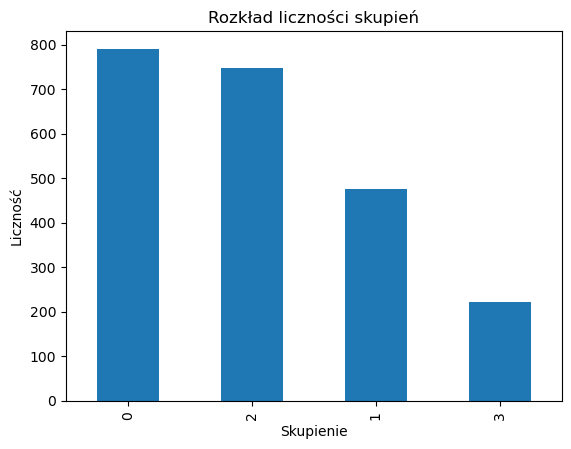

In [61]:
# Tworzenie wykresu słupkowego
marketing_df["predicted_class"].value_counts().plot(kind="bar")

# Opisy osi i tytuł
plt.xlabel("Skupienie")
plt.ylabel("Liczność")
plt.title("Rozkład liczności skupień")

# Wyświetlenie wykresu
plt.show()

In [62]:
# Grupowanie danych po segmencie (dane surowe) i obliczenie średnich
means = marketing_df.groupby("predicted_class")[predictors].mean()

means.head()

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,CustomerTenure,Age,AcceptedAnyCmp,IsAdvancedDegree,IsTogether
predicted_class,,,,,,,,,,,,,,,,,,,,
0,71383.178255,0.111252,0.379267,49.145386,556.264539,46.529709,336.812895,70.834387,48.142857,64.281290,1.864728,5.515803,5.259166,8.418458,3.517067,555.673831,47.375474,0.302149,0.517067,0.701643
1,41432.841053,0.627368,0.583158,48.618947,150.037895,9.193684,55.684211,13.183158,9.303158,25.602105,2.421053,3.341053,1.172632,4.450526,6.187368,535.105263,45.694737,0.000000,0.469474,0.000000
2,38211.454485,0.681392,0.535475,49.760375,90.502008,6.524766,35.759036,9.425033,6.590361,21.205489,2.277108,2.779116,0.772423,3.943775,6.265060,525.164659,44.686747,0.000000,0.417671,1.000000
3,50192.733184,0.439462,0.699552,47.914798,435.320628,10.825112,79.766816,11.125561,7.394619,42.327354,2.825112,4.753363,2.582960,5.560538,6.515695,542.251121,47.192825,1.000000,0.502242,0.627803


In [63]:
# Grupowanie danych po segmencie (dane wyskalowane) i obliczenie średnich
means_scaled = scaled_marketing_df.groupby("predicted_class")[predictors].mean()

means.head()

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,CustomerTenure,Age,AcceptedAnyCmp,IsAdvancedDegree,IsTogether
predicted_class,,,,,,,,,,,,,,,,,,,,
0,71383.178255,0.111252,0.379267,49.145386,556.264539,46.529709,336.812895,70.834387,48.142857,64.281290,1.864728,5.515803,5.259166,8.418458,3.517067,555.673831,47.375474,0.302149,0.517067,0.701643
1,41432.841053,0.627368,0.583158,48.618947,150.037895,9.193684,55.684211,13.183158,9.303158,25.602105,2.421053,3.341053,1.172632,4.450526,6.187368,535.105263,45.694737,0.000000,0.469474,0.000000
2,38211.454485,0.681392,0.535475,49.760375,90.502008,6.524766,35.759036,9.425033,6.590361,21.205489,2.277108,2.779116,0.772423,3.943775,6.265060,525.164659,44.686747,0.000000,0.417671,1.000000
3,50192.733184,0.439462,0.699552,47.914798,435.320628,10.825112,79.766816,11.125561,7.394619,42.327354,2.825112,4.753363,2.582960,5.560538,6.515695,542.251121,47.192825,1.000000,0.502242,0.627803


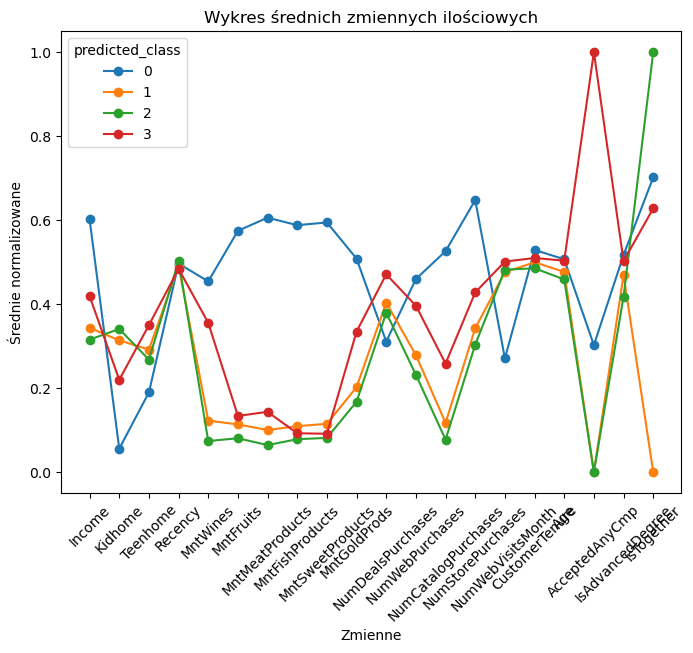

In [64]:
means_scaled.T.plot(marker="o", linestyle="-", figsize=(8, 6))

# Opisy osi i tytuł
plt.xlabel("Zmienne")
plt.ylabel("Średnie normalizowane")
plt.title("Wykres średnich zmiennych ilościowych")


# Wymuszenie wyświetlenia wszystkich etykiet i obrót
plt.xticks(ticks=range(len(means_scaled.T.index)), labels=means_scaled.T.index, rotation=45)

plt.show()

In [65]:
filtered_df = marketing_df[marketing_df["predicted_class"] == 3]

filtered_df.head(20)

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,IsAdvancedDegree,IsTogether,TotalAcceptedCmp,AcceptedAnyCmp,Age,CustomerTenure,predicted_class
9,5899,1950,PhD,Together,5648.0,1,1,2014-03-13,68,28.0,0,6,1.0,1,13.0,1,1,0,0,13,1,0,0,0,0,0,0,1,1,1,1,65,294,3
22,1993,1949,PhD,Married,58607.0,0,1,2012-12-23,63,867.0,0,86,0.0,0,19.0,3,2,3,9,8,0,1,0,0,0,0,0,1,1,1,1,66,739,3
32,5710,1970,Graduation,Together,40548.0,0,1,2012-10-10,31,110.0,0,5,2.0,0,3.0,2,2,1,4,5,0,1,0,0,0,0,0,0,1,1,1,45,813,3
73,8132,1975,PhD,Married,60631.0,1,1,2013-04-05,88,565.0,6,65,0.0,6,19.0,5,9,2,8,7,0,1,0,0,0,0,0,1,1,1,1,40,636,3
79,1618,1965,Graduation,Together,56046.0,0,0,2013-01-02,9,577.0,0,64,0.0,0,51.0,2,10,1,8,8,1,0,0,0,0,0,1,0,1,1,1,50,729,3
86,273,1970,Master,Married,36138.0,1,1,2013-07-16,48,130.0,0,16,0.0,0,5.0,5,3,1,4,7,0,1,0,0,0,0,0,1,1,1,1,45,534,3
87,4452,1957,Graduation,Single,50388.0,0,1,2014-05-28,3,292.0,6,37,0.0,3,34.0,4,6,1,6,7,0,1,0,1,0,0,1,0,0,2,1,58,218,3
96,7247,1960,Graduation,Widow,47916.0,0,1,2012-11-22,72,505.0,0,26,0.0,0,75.0,5,7,4,6,6,0,1,0,0,0,0,0,0,0,1,1,55,770,3
112,3267,1963,Master,Together,57288.0,0,1,2014-06-25,27,527.0,0,21,0.0,0,60.0,3,8,1,8,6,0,1,0,0,0,0,0,1,1,1,1,52,190,3
138,7660,1973,PhD,Alone,35860.0,1,1,2014-05-19,37,15.0,0,8,4.0,2,20.0,2,1,1,2,5,1,0,0,0,0,0,1,1,0,1,1,42,227,3


In [66]:
# W ramach pogłębionej interpretacji wyników możemy próbować identyfikować "najbardziej typowego" przedstawiciela swojej grupy.
# Tutaj pomocna może być informacja o odległości danego przypadku od środka skupienia.
# Najbardziej typoty przypadek - reprezentant skupienia to przypadek, który ma najbliżej do środka skupienia.

#potrzebujemy zatem funkcji obliczającej odległość od środka

def compute_distances_to_centroid(df, predictors, cluster_column):
    """
    Oblicza odległości każdego punktu od centroidu swojego klastra.

    Parametry:
    - df: DataFrame zawierający dane
    - predictors: lista nazw kolumn zmiennych ilościowych
    - cluster_column: nazwa kolumny z przypisanymi klastrami

    Zwraca:
    - Tablicę NumPy z odległościami do centroidów
    """
    # Obliczenie centroidów (średnich wartości w każdym klastrze)
    centroids = df.groupby(cluster_column)[predictors].mean()

    # Obliczanie odległości dla każdego wiersza
    distances = np.array([
        np.linalg.norm(df.loc[i, predictors] - centroids.loc[df.loc[i, cluster_column]])
        for i in df.index
    ])

    return distances


In [87]:
# Przykład użycia
distance_to_centroid = compute_distances_to_centroid(scaled_marketing_df, predictors, "predicted_class")

# Zapis wyników do DataFrame
scaled_marketing_df["distance_to_centroid"] = distance_to_centroid
marketing_df["distance_to_centroid"] = distance_to_centroid

In [90]:
#Dzięki temu możesz poznać "przedstawiciela" segmentu 0 — idealnego kandydata do stworzenia persony marketingowej!
filtered_df = marketing_df[marketing_df["predicted_class"] == 0]

# Sortowanie po kolumnie "distance_to_centroid" rosnąco
filtered_df = filtered_df.sort_values(by="distance_to_centroid", ascending=True)


filtered_df.head(1)
# Podgląd cech najbardziej typowego klienta w segmencie (np. 0)
typowy_klient = filtered_df.head(1)[predictors].T
typowy_klient.columns = ['Wartość']
display(typowy_klient)

# To klient w średnim wieku, raczej tradycyjny, bez aktywnej odpowiedzi na kampanie, z przewagą zakupów offline.
# Preferuje produkty codziennego użytku i okazjonalnie luksusowe.
# Prawdopodobnie warto inwestować w kanały stacjonarne i lojalnościowe, a mniej w kampanie cyfrowe.


,Wartość
Income,46524.0
Kidhome,0.0
Teenhome,1.0
Recency,70.0
MntWines,31.0
MntFruits,19.0
MntMeatProducts,35.0
MntFishProducts,26.0
MntSweetProducts,14.0
MntGoldProds,52.0


In [ ]:
#Ocenimy teraz ten model pod kątem miar oraz za pomocą wykresów

# Spróbujmy ocenić model

#     Wskaźnik sylwetki
#     Wykres sylwetki

# Blisko 1 → Bardzo dobre klastrowanie, obiekty dobrze dopasowane do swoich klastrów
# Około 0.5 → Średnia jakość klastrowania, niektóre punkty mogą być źle przypisane
# Blisko 0 → Punkty leżą na granicy klastrów, możliwe nakładanie się klas
# Wartości ujemne → Punkty są przypisane do złych klastrów

In [ ]:
from sklearn.metrics import silhouette_score

# Obliczenie wskaźnika sylwetki
silhouette_avg = silhouette_score(scaled_marketing_df[predictors], scaled_marketing_df["predicted_class"])

print(f"Wartość wskaźnika sylwetki: {silhouette_avg:.4f}")

In [ ]:
from sklearn.metrics import silhouette_samples, silhouette_score

def plot_silhouette(data, cluster_column, predictors):
    """
    Tworzy wykres wskaźnika sylwetki dla danych po klasteryzacji.

    Parametry:
    - data: DataFrame zawierający przeskalowane zmienne predykcyjne oraz kolumnę z etykietami klastrów
    - cluster_column: nazwa kolumny zawierającej etykiety klas
    - predictors: lista nazw kolumn zawierających cechy używane do klasteryzacji
    """

    # Obliczenie wartości wskaźnika sylwetki dla każdego punktu
    silhouette_vals = silhouette_samples(data[predictors], data[cluster_column])

    # Pobranie unikalnych etykiet klas
    clusters = np.unique(data[cluster_column])

    # Tworzenie wykresu
    plt.figure(figsize=(8, 6))

    y_lower = 0
    for cluster in clusters:
        # Pobranie wartości sylwetki dla danego klastra
        cluster_vals = silhouette_vals[data[cluster_column] == cluster]
        cluster_vals.sort()

        y_upper = y_lower + len(cluster_vals)
        plt.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_vals, label=f"Skupienie {cluster}")

        y_lower = y_upper

    # Rysowanie średniego wskaźnika sylwetki jako pionowej linii
    silhouette_avg = silhouette_score(data[predictors], data[cluster_column])
    plt.axvline(x=silhouette_avg, color="red", linestyle="--", label="Średnia sylwetka")

    # Opisy osi i tytuł
    plt.xlabel("Wartość wskaźnika sylwetki")
    plt.ylabel("Obserwacje w skupieniach")
    plt.title("Wykres wskaźnika sylwetki dla skupień")

    # Legenda
    plt.legend()

    # Wyświetlenie wykresu
    plt.show()

In [ ]:
plot_silhouette(scaled_marketing_df,"predicted_class",predictors)

In [ ]:
# Calinski-Harabasz Score (wartości większe = lepsze) – mierzy stosunek wariancji między klastrami do wariancji wewnątrz klastrów

# Jest to stosunek wariancji międzyklastrowej do wariancji wewnątrzklastrowej. Brak uniwersalnych progów ale w praktyce:

#     ≥ 500 – bardzo dobrze oddzielone klastry (dla dużych zbiorów danych).
#     100-500 – dobra klasteryzacja.
#     < 100 – klastry są słabo oddzielone.
#     Bliskie 0 – bardzo słaba klasteryzacja, przypomina losowy podział.

# Davies-Bouldin Score (wartości niższe = lepsze) – mierzy, jak bardzo klastry są od siebie oddzielone Interpretacja:

#     Blisko 0 – bardzo dobrze oddzielone klastry.
#     0.5 – 1.5 – dobra jakość klastrów.
#     > 2 – klastry zaczynają się nakładać i są źle rozdzielone.
#     > 3 – bardzo słaba klasteryzacja.

# Wartość bliska 0 oznacza dobrze oddzielone klastry. Jednak dla różnych zbiorów danych różne wartości mogą być uznawane za dobre.


In [ ]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

# Obliczenie wskaźników
calinski_harabasz = calinski_harabasz_score(scaled_marketing_df[predictors], scaled_marketing_df["predicted_class"])
davies_bouldin = davies_bouldin_score(scaled_marketing_df[predictors], scaled_marketing_df["predicted_class"])

# Wyświetlenie wyników
print(f"Wartość wskaźnika Calinskiego-Harabasza: {calinski_harabasz:.4f}")
print(f"Wartość wskaźnika Daviesa-Bouldina: {davies_bouldin:.4f}")

In [71]:
# Wizualizacja i ocena jakości segmentacji

# Po przeprowadzeniu segmentacji chcemy sprawdzić, czy nasze grupy są dobrze rozdzielone.
# Ponieważ mamy wiele cech, trudno to zobaczyć bezpośrednio,dlatego stosujemy redukcję wymiarów – PCA (analiza głównych składowych) lub t-SNE.
# Te metody pozwalają nam przedstawić dane na wykresie 2D, zachowując jak najwięcej informacji o strukturze klastrów. 
# Jeśli klastry są dobrze oddzielone, oznacza to, że segmentacja przebiegła poprawnie i rzeczywiście znaleźliśmy grupy o różnych cechach.
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
def visualize_clusters(df, predictors, cluster_col, method='PCA'):
    """
    Wizualizuje klastry w 2D przy użyciu PCA lub t-SNE, dodając centroidy.
    
    Parametry:
    - df: DataFrame zawierający dane
    - predictors: lista kolumn do redukcji wymiarów
    - cluster_col: nazwa kolumny zawierającej przypisane klastry
    - method: 'PCA' lub 't-SNE' (domyślnie 'PCA')
    """
    
    # Redukcja wymiarów
    if method == 'PCA':
        reducer = PCA(n_components=2)
        x_label, y_label, title = "Pierwsza składowa PCA", "Druga składowa PCA", "Klastry w PCA"
    elif method == 't-SNE':
        reducer = TSNE(n_components=2, perplexity=30, random_state=42)
        x_label, y_label, title = "Pierwszy wymiar t-SNE", "Drugi wymiar t-SNE", "Klastry w t-SNE"
    else:
        raise ValueError("Metoda musi być 'PCA' lub 't-SNE'")
    
    # Przekształcenie danych
    X_transformed = reducer.fit_transform(df[predictors])
    
    # Dodanie centroidów – obliczamy średnie wartości dla każdego klastra
    df_transformed = df.copy()
    df_transformed['X1'] = X_transformed[:, 0]
    df_transformed['X2'] = X_transformed[:, 1]
    
    centroids = df_transformed.groupby(cluster_col)[['X1', 'X2']].mean()
    
    # Tworzenie wykresu
    plt.figure(figsize=(6, 5))
    sns.scatterplot(x='X1', y='X2', hue=cluster_col, palette='Set1', data=df_transformed, alpha=0.7)
    
    # Dodanie centroidów jako czarnych "X"
    plt.scatter(centroids['X1'], centroids['X2'], marker="X", s=200, c="black", label="Centroidy")
    
    # Opisy wykresu
    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.legend(title="Skupienie")
    plt.show()

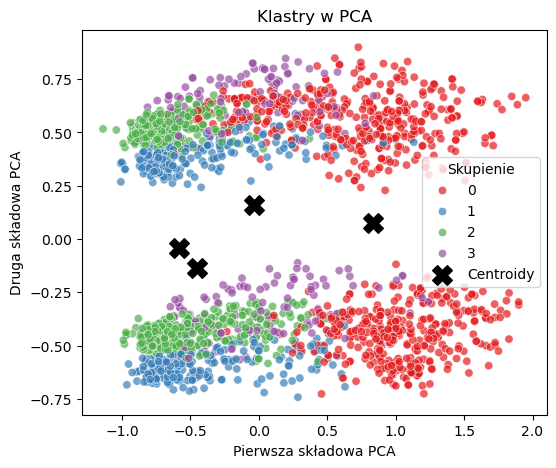

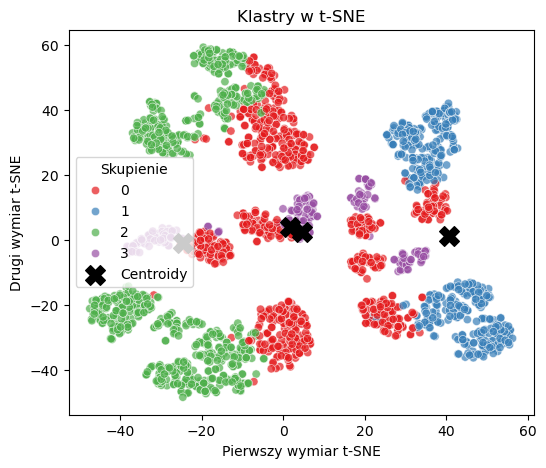

In [72]:
visualize_clusters(scaled_marketing_df, predictors, 'predicted_class', method='PCA')
visualize_clusters(scaled_marketing_df, predictors, 'predicted_class', method='t-SNE')

In [ ]:
# Wnioski z PCA:

#     Klastry 1 i 2 są dość dobrze separowane.

#     Klastry 0 i 3 się częściowo przenikają, ale nie całkowicie.

#     Taki układ sugeruje, że PCA pokazuje jakąś strukturę, ale nie idealnie rozdziela grup.

 
# Wnioski z t-SNE:

#     Klastry są lepiej widocznie oddzielone niż w PCA.

#     Klaster 2 jest kompaktowy i wyraźny.

#     Klaster 3 lekko się rozciąga, ale nadal stanowi zwartą strukturę.

#     Centroidy umieszczone logicznie względem rozrzutu punktów.

In [ ]:
# Co jeszcze można zrobić? Zbudujemy model innymi metodami

#     W modelu k-średnich podajemy z góry liczbę skupień - przyjmijmy że są 4 skupienia
#     Sieci neuronowe Kohonena - przyjmujemy, że mamy 4 skupienia
#     Metoda GMM - przyjmujemy że mamy 4 skupienia
#     DBSCAN - nie możemy tego założyć
#     Budujemy model i od razu przypisujemy do kolumny z danymi predykcję modelu
#     Predykcję zapisujemy zarówno do oryginalnych danych jak i do przeskalowanych danych
#     Oceniamy model znanymi sposobami
#     Możemy porównać zgodność modeli za pomocą wskaźnika Randa!


In [75]:
# Metoda K-średnich
from sklearn.cluster import KMeans
import warnings
warnings.simplefilter(action='ignore', category=UserWarning)

# Algorytm k-średnich
#podaj liczbę skupień
n_clusters= 4
seed = 42
kmeans_model = KMeans(n_clusters=n_clusters, random_state=seed)

#wykonaj model i przypisz predykcję do tablicy z wynikami
kmeans_model_classes = kmeans_model.fit_predict(scaled_marketing_df[predictors])

# zapisz predykcję do kolumny w ramce danych
marketing_df['predicted_class'] = kmeans_model_classes

# zapisz predykcję do kolumny w ramce danych wystandaryzowanych
scaled_marketing_df['predicted_class'] = kmeans_model_classes

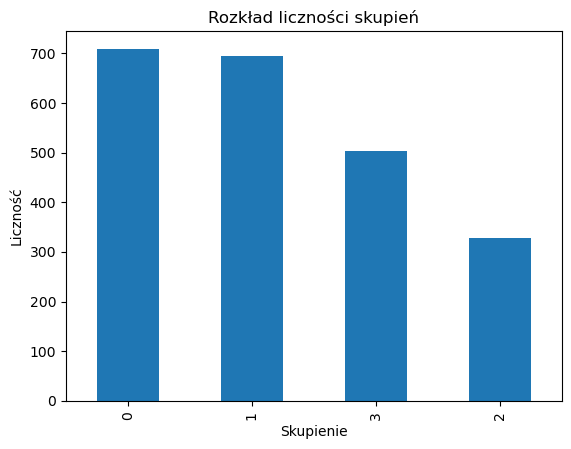

In [76]:
# Tworzenie wykresu słupkowego
marketing_df["predicted_class"].value_counts().plot(kind="bar")

# Opisy osi i tytuł
plt.xlabel("Skupienie")
plt.ylabel("Liczność")
plt.title("Rozkład liczności skupień")

# Wyświetlenie wykresu
plt.show()

In [77]:
#Metoda GMM
import warnings
warnings.simplefilter("ignore", category=UserWarning)

from sklearn.mixture import GaussianMixture

# Liczba klastrów (analogicznie do K-Means)
n_clusters = 4

gmm_model = GaussianMixture(n_components=n_clusters, random_state=seed)

# Dopasowanie modelu i przypisanie klas
gmm_model_classes = gmm_model.fit_predict(scaled_marketing_df[predictors])

# Zapis predykcji do DataFrame
marketing_df['predicted_class'] = gmm_model_classes
scaled_marketing_df['predicted_class'] = gmm_model_classes

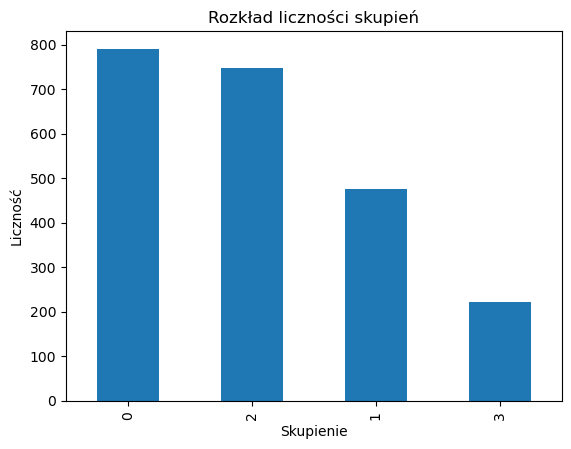

In [68]:
# Tworzenie wykresu słupkowego
marketing_df["predicted_class"].value_counts().plot(kind="bar")

# Opisy osi i tytuł
plt.xlabel("Skupienie")
plt.ylabel("Liczność")
plt.title("Rozkład liczności skupień")

# Wyświetlenie wykresu
plt.show()

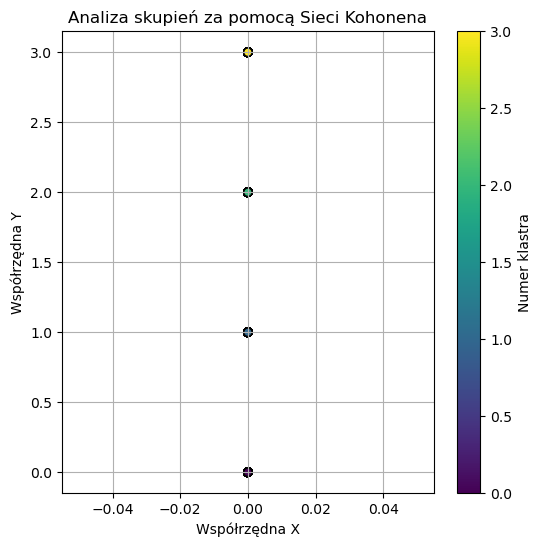

In [80]:
#Sieci neuronowe Kohonena

from minisom import MiniSom

# Parametry SOM
map_size = (1, 4)  # Rozmiar siatki (np. 5x5)
input_len = len(predictors)  # Liczba zmiennych wejściowych
sigma = 1.0  # Promień sąsiedztwa
learning_rate = 0.5  # Tempo uczenia

# Inicjalizacja i trenowanie SOM
som = MiniSom(map_size[0], map_size[1], input_len, sigma=sigma, learning_rate=learning_rate, random_seed=seed)
som.random_weights_init(scaled_marketing_df[predictors].values)
som.train_random(scaled_marketing_df[predictors].values, num_iteration=1000)

# Przypisanie klastrów do obserwacji
winner_nodes = np.array([som.winner(x) for x in scaled_marketing_df[predictors].values])  # Współrzędne najlepszych neuronów
cluster_labels = np.ravel_multi_index(winner_nodes.T, dims=map_size)  # Zamiana współrzędnych na jedną etykietę klastra

# Zapis predykcji do DataFrame
marketing_df['predicted_class'] = cluster_labels
scaled_marketing_df['predicted_class'] = cluster_labels


#Wizualizacja wyników
plt.figure(figsize=(6, 6))
plt.scatter(winner_nodes[:, 0], winner_nodes[:, 1], c=cluster_labels, cmap="viridis", edgecolors='k')
plt.colorbar(label="Numer klastra")
plt.title("Analiza skupień za pomocą Sieci Kohonena")
plt.xlabel("Współrzędna X")
plt.ylabel("Współrzędna Y")
plt.grid()
plt.show()



In [ ]:
# Rozproszenie punktów – punktów nie ma wszędzie, więc nie wszystkie 16 neuronów są użyte, co może oznaczać,
# że klienci naturalnie skupiają się w mniejszej liczbie sensownych grup.

# Zagęszczenia – jeśli jakieś obszary mają więcej punktów, to może sugerować:
#    - popularne typy klientów (częstsze profile),
#    - większe klastry.

# Rozdzielność – punkty różnych kolorów są raczej rozproszone przestrzennie, co świadczy o tym,
# że sieć SOM znalazła sensowne separacje między segmentami.

# Potencjalne grupy – SOM potrafi ujawnić nieregularne, nieliniowe struktury w danych (czego np. KMeans nie widzi).
# Tutaj można sądzić, że SOM pogrupował klientów bardziej „naturalnie” niż klasyczne algorytmy.

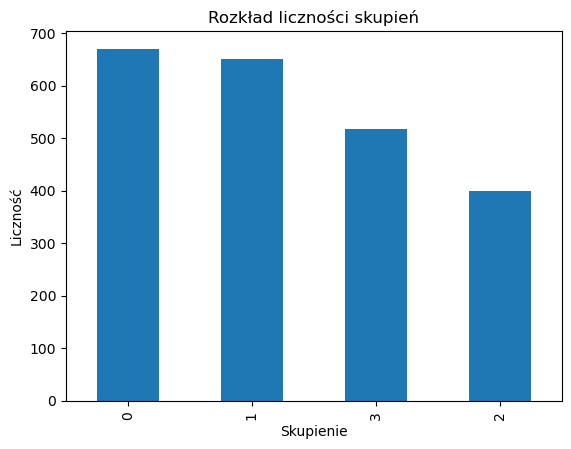

In [81]:
# Tworzenie wykresu słupkowego
marketing_df["predicted_class"].value_counts().plot(kind="bar")

# Opisy osi i tytuł
plt.xlabel("Skupienie")
plt.ylabel("Liczność")
plt.title("Rozkład liczności skupień")

# Wyświetlenie wykresu
plt.show()

In [82]:
# Metoda DBSCAN
# Działanie algorytmu jest wrażliwe na wartość "eps"!


from sklearn.cluster import DBSCAN

# Parametry DBSCAN
eps = 0.99  # Maksymalna odległość do sąsiada w klastrze
min_samples = 5  # Minimalna liczba punktów do utworzenia klastra

dbscan_model = DBSCAN(eps=eps, min_samples=min_samples)

# Wykonaj model i przypisz predykcję do tablicy z wynikami
dbscan_model_classes = dbscan_model.fit_predict(scaled_marketing_df[predictors])

# Zapisz predykcję do kolumny w ramce danych
marketing_df['predicted_class'] = dbscan_model_classes

# Zapisz predykcję do kolumny w ramce danych wystandaryzowanych
scaled_marketing_df['predicted_class'] = dbscan_model_classes

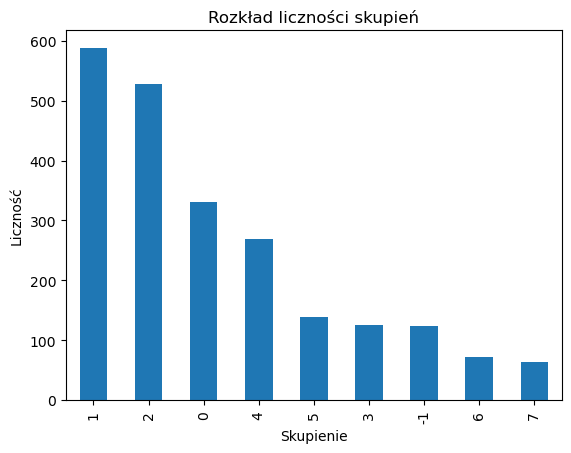

In [83]:
# Tworzenie wykresu słupkowego
marketing_df["predicted_class"].value_counts().plot(kind="bar")

# Opisy osi i tytuł
plt.xlabel("Skupienie")
plt.ylabel("Liczność")
plt.title("Rozkład liczności skupień")

# Wyświetlenie wykresu
plt.show()

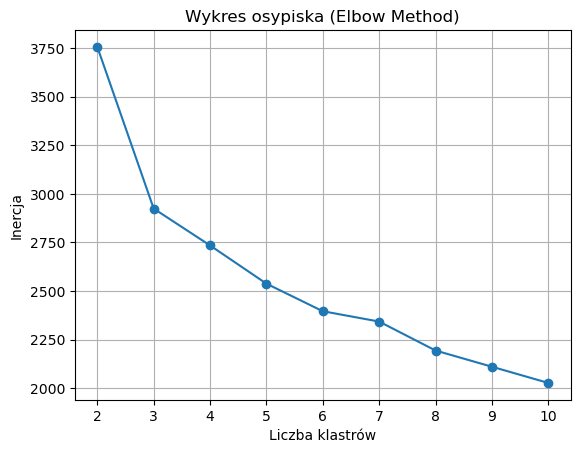

,Liczba skupień,Wskaźnik sylwetki
0,2,0.141953
1,3,0.168812
2,4,0.165013
3,5,0.164201
4,6,0.167120
5,7,0.150933
6,8,0.173688
7,9,0.173571
8,10,0.182563


In [85]:
# Być może inna liczba skupień pozwoliłaby uzyskać lepszy wynik?

#     Zbudujemy wiele modeli dla różnych wartości k
#     Wynik porównamy za pomocą wykresu osypiska dla wartości inercji
#     Sprawdzimy też wartości indeksu sylwetki
from sklearn.metrics import silhouette_score

# Zakres liczby skupień
cluster_range = range(2, 11)

# Listy do zapisania wyników
inertia_values = []
silhouette_values = []

# Pętla dla różnej liczby skupień
for k in cluster_range:
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(scaled_marketing_df[predictors])
    
    inertia_values.append(model.inertia_)
    silhouette_values.append(silhouette_score(scaled_marketing_df[predictors], labels))
    

# Wykres osypiska (Elbow Method)
plt.plot(cluster_range, inertia_values, marker="o", linestyle="-")
plt.xlabel("Liczba klastrów")
plt.ylabel("Inercja")
plt.title("Wykres osypiska (Elbow Method)")
plt.grid(True)
plt.show()

# Tabelka wskaźników sylwetki
df_silhouette = pd.DataFrame({"Liczba skupień": cluster_range, "Wskaźnik sylwetki": silhouette_values})
df_silhouette.head(10)

In [ ]:
# Wykres łokcia – Inertia (Wewnątrzklastrowa suma kwadratów):

#  Widzimy, że spadek wartości „inertia” zaczyna się wypłaszczać po około 4–5 klastrach.
#  Punkt „zagięcia” krzywej (czyli "łokcia") to miejsce, w którym dodawanie kolejnych klastrów przestaje drastycznie poprawiać dopasowanie.
#  W Twoim przypadku ten punkt pojawia się gdzieś przy 4 lub 5 klastrach, co czyni je dobrymi kandydatami.


# Wskaźnik sylwetki – Spójność i separacja klastrów:
# Silhouette score (wartość między -1 a 1, im wyższa tym lepiej)
# Najwyższy wynik uzyskano przy 10 klastrach (0.183), jednak warto zauważyć, że różnice w wartościach między 8, 9 i 10 klastrami są niewielkie.
# Wybór 10 może dać największą separację, ale może też prowadzić do nadsegmentacji, 
#jeśli interpretacja tych grup będzie trudna lub niepraktyczna biznesowo.

In [ ]:
# Wpływ na decyzje  dokonanych analiz:

#     Lepsze targetowanie kampanii:

#         Możesz przypisać konkretne kampanie do konkretnych grup klientów, np.:

#             Segment 0 – stacjonarni, tradycyjni klienci → katalog, rabaty offline.

#             Segment 3 – cyfrowi, aktywni → e-mail marketing, kampanie social media.

#     Personalizacja komunikacji i oferty:

#     Różne grupy mają różne potrzeby i style zakupowe — możesz dostosować język, grafikę, produkty.

#     Alokacja budżetu marketingowego:

#     Nie musisz rozrzucać środków równo — inwestuj tam, gdzie jest największy potencjał konwersji lub lojalności.

#     Wizualizacja i zrozumienie klientów:

#     Zespół sprzedaży, marketingu czy produktu może łatwiej „zobaczyć”,
#     z kim mają do czynienia — nie jako zbiór danych, tylko realnych ludzi o konkretnych cechach.
#     Podstawa do dalszych działań:

#         Segmentacja to nie koniec, tylko początek:

#             scoring leadów,

#             rekomendacje produktów,


